In [219]:
from pathlib import Path


COURSE_SOURCE_REF = "v0.2.2"
COURSE_REPOSITORY = "https://gitlab.unimelb.edu.au/dream/dream-gym.git"

setup_diagnostic = None

if setup_diagnostic is not None:
    print(setup_diagnostic)


In [220]:
RUN_MODE = "full"
if RUN_MODE not in {"smoke", "full"}:
    raise ValueError("RUN_MODE must be 'smoke' or 'full'")

FULL_EVALUATION_CHECKPOINT_COUNT = 4
if (
    isinstance(FULL_EVALUATION_CHECKPOINT_COUNT, bool)
    or not isinstance(FULL_EVALUATION_CHECKPOINT_COUNT, int)
    or FULL_EVALUATION_CHECKPOINT_COUNT < 1
):
    raise ValueError("FULL_EVALUATION_CHECKPOINT_COUNT must be a positive integer")

SHOW_CHECKPOINT_TRAJECTORIES = True
CHECKPOINT_TRAJECTORIES_TO_SHOW = "all"
if not (
    CHECKPOINT_TRAJECTORIES_TO_SHOW == "all"
    or (
        isinstance(CHECKPOINT_TRAJECTORIES_TO_SHOW, int)
        and not isinstance(CHECKPOINT_TRAJECTORIES_TO_SHOW, bool)
        and CHECKPOINT_TRAJECTORIES_TO_SHOW > 0
    )
):
    raise ValueError(
        "CHECKPOINT_TRAJECTORIES_TO_SHOW must be 'all' or a positive integer"
    )
SHOW_CHECKPOINT_TIME_SERIES = False
GENERATE_CHECKPOINT_GIFS = False
GENERATE_COMBINED_FINAL_GIF = True
GENERATE_DOMAIN_RANDOMIZED_FINAL_GIF = False

OUTPUT_ROOT = Path("notebook_outputs") / "rl-reward-shaping-and-training"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)


In [221]:
import copy
import csv
import gymnasium as gym
import json
import math
import dreamgym
dreamgym_source = Path(dreamgym.__file__).resolve()


import matplotlib.pyplot as plt
import numpy as np
from dreamgym.envs.road import Road
from dreamgym.evaluation import MetricSet, PerformanceMetric, PolicySpec
from dreamgym.evaluation.autonomous_driving import (
    AutonomousDrivingEvaluationConfig,
    InitialStateValueParameter,
    UniformMultiplierParameter,
    UncertaintySweep,
    compute_autonomous_driving_metrics,
    evaluate_policies_over_sweep,
    metric_by_name,
    rerun_sweep_rollout,
    simulate_policy,
)
from dreamgym.policies.autonomous_driving import RLPolicy
from dreamgym.training.autonomous_driving import (
    RewardContext,
    config_to_dict,
    default_training_config,
    load_model_and_config_for_evaluation,
    train,
)
from dreamgym.training.autonomous_driving.envs import (
    make_env_from_evaluation_view,
)
from dreamgym.training.autonomous_driving.resolution import (
    evaluation_road_specs_from_snapshot,
)
from dreamgym.visualization.autonomous_driving import (
    plot_road_from_spec,
    plot_simulation_results,
    save_figure,
)


### 1.6 Notebook output formatting


In [222]:
from html import escape
from IPython.display import HTML, Image as NotebookImage, display

def _format_table_value(value, digits=4):
    if value is None:
        return "—"
    if isinstance(value, (float, np.floating)):
        return f"{float(value):.{digits}g}"
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, (dict, list, tuple)):
        return json.dumps(value, default=str, ensure_ascii=False)
    return str(value)

def display_records(rows, *, columns=None, title=None, digits=4):
    records = tuple(dict(row) for row in rows)
    if not records:
        display(HTML("<p><em>No rows were produced.</em></p>"))
        return records
    if columns is None:
        columns = tuple(dict.fromkeys(key for row in records for key in row))
    else:
        columns = tuple(columns)
    caption = (
        f'<caption style="caption-side:top;text-align:left;font-weight:600">'
        f"{escape(str(title))}</caption>"
        if title else ""
    )
    header = "".join(f"<th>{escape(str(column))}</th>" for column in columns)
    body = "".join(
        "<tr>" + "".join(
            f"<td>{escape(_format_table_value(row.get(column), digits))}</td>"
            for column in columns
        ) + "</tr>"
        for row in records
    )
    display(HTML(
        '<table class="dataframe" style="margin-bottom:1em">'
        + caption
        + f"<thead><tr>{header}</tr></thead><tbody>{body}</tbody></table>"
    ))
    return records

def display_mapping(
    mapping,
    *,
    key_label="field",
    value_label="value",
    title=None,
    digits=4,
):
    retained = dict(mapping)
    display_records(
        ({key_label: key, value_label: value} for key, value in retained.items()),
        columns=(key_label, value_label),
        title=title,
        digits=digits,
    )
    return retained


### 1.7 Shared execution settings


In [223]:
TRAINING_SETTINGS = {
    "smoke": {
        "combined_transitions": 128,
        "domain_randomized_transitions": 128,
        "rollout_transitions": 64,
        "n_envs": 1,
        "n_epochs": 1,
        "batch_size": 32,
        "evaluation_steps": 40,
        "evaluation_checkpoint_count": 1,
        "generated_road_case_count": 1,
        "sweep_samples": 2,
        "sweep_steps": 40,
    },
    "full": {
        "combined_transitions": 250_000,
        "domain_randomized_transitions": 250_000,
        "rollout_transitions": 1_024,
        "n_envs": 4,
        "n_epochs": 4,
        "batch_size": 64,
        "evaluation_steps": 2_000,
        "evaluation_checkpoint_count": FULL_EVALUATION_CHECKPOINT_COUNT,
        "generated_road_case_count": 4,
        "sweep_samples": 16,
        "sweep_steps": 1_500,
    },
}
MODE = copy.deepcopy(TRAINING_SETTINGS[RUN_MODE])


## 2. Experimental foundations


In [224]:
TRAINING_FIXED_ROAD_SPEC = {
    "elements": [
        {
            "geometry": {"type": "straight", "length_m": 180.0},
            "speed_limit_kph": 70.0,
            "cross_section_width_interpolation": "constant",
            "lanes": {
                "reference_line_role": "lane_center",
                "reference_lane": {
                    "width_m": {"start": 3.6, "end": 3.6},
                    "surface": "tarmac",
                },
            },
        },
        {"geometry": {"type": "circular_arc", "curvature_per_m": 1.0 / 180.0, "sweep_angle_deg": 30.0}, "speed_limit_kph": 60.0},
        {"geometry": {"type": "straight", "length_m": 160.0}, "speed_limit_kph": 70.0},
        {"geometry": {"type": "circular_arc", "curvature_per_m": -1.0 / 150.0, "sweep_angle_deg": 35.0}, "speed_limit_kph": 60.0},
        {"geometry": {"type": "straight", "length_m": 500.0}, "speed_limit_kph": 70.0},
    ],
}
training_fixed_road = Road(road_spec=TRAINING_FIXED_ROAD_SPEC)
TRAINING_FIXED_ROAD_SPEC = training_fixed_road.requested_road_spec

fixed_evaluation_road_spec = {
    "elements": [
        {
            "geometry": {"type": "straight", "length_m": 200.0},
            "speed_limit_kph": 70.0,
            "cross_section_width_interpolation": "constant",
            "lanes": {
                "reference_line_role": "lane_center",
                "reference_lane": {
                    "width_m": {"start": 3.6, "end": 3.6},
                    "surface": "tarmac",
                },
            },
        },
        {"geometry": {"type": "circular_arc", "curvature_per_m": -1.0 / 130.0, "sweep_angle_deg": 25.0}, "speed_limit_kph": 60.0},
        {"geometry": {"type": "straight", "length_m": 140.0}, "speed_limit_kph": 70.0},
        {"geometry": {"type": "circular_arc", "curvature_per_m": 1.0 / 110.0, "sweep_angle_deg": 30.0}, "speed_limit_kph": 60.0},
        {"geometry": {"type": "straight", "length_m": 550.0}, "speed_limit_kph": 70.0},
    ],
}
fixed_evaluation_road = Road(road_spec=fixed_evaluation_road_spec)
FIXED_EVALUATION_ROAD_SPECS = [fixed_evaluation_road.requested_road_spec]


### 2.3 Reward-function definition



In [225]:
def driving_reward(context: RewardContext, coefficients):
    """Return (total, named terms) for one environment step.

    Reads only the public RewardContext. Three continuous terms (lane, speed,
    progress) are scaled by coefficients; three event terms fire once, on the
    step where the episode ends.
    """
    ground_truth = context.ground_truth
    current_progress_m = float(ground_truth["reference_line_progress_m"])
    previous_progress_m = current_progress_m
    if context.previous_ground_truth is not None:
        previous_progress_m = float(
            context.previous_ground_truth["reference_line_progress_m"]
        )
    lateral_error_m = float(ground_truth["lateral_error_from_target_line_m"])
    heading_error_rad = float(ground_truth["heading_error_from_target_line_rad"])
    speed_mps = float(ground_truth["ground_truth_body_longitudinal_velocity_mps"])
    recommended_speed_mps = float(ground_truth["recommended_speed_mps"])

    # Continuous terms: bounded in [0, 1] for lane and speed, unbounded for progress.
    lane = 1.0 / (1.0 + abs(lateral_error_m))
    heading_gate = max(0.0, math.cos(heading_error_rad))
    speed = heading_gate / (1.0 + abs(speed_mps - recommended_speed_mps))
    progress = current_progress_m - previous_progress_m

    # Event terms: paid once, only on the step that ends the episode.
    termination_reasons = context.info.get("termination_reasons", {})
    completion = 0.0
    lateral_termination = 0.0
    pure_truncation = 0.0
    if context.terminated and termination_reasons.get(
        "road_progress_completion_threshold_reached"
    ):
        completion = float(coefficients["road_progress_completion_reward"])
    if context.terminated and termination_reasons.get(
        "absolute_lateral_error_from_target_line_above_upper_bound"
    ):
        lateral_termination = float(
            coefficients["absolute_lateral_error_from_target_line_termination_reward"]
        )
    if context.truncated and not context.terminated:
        pure_truncation = float(coefficients["truncation_without_termination_reward"])

    total = (
        float(coefficients["k_lane"]) * lane
        + float(coefficients["k_speed"]) * speed
        + float(coefficients["k_progress"]) * progress
        + completion
        + lateral_termination
        + pure_truncation
    )
    terms = {
        "lane": lane,
        "speed": speed,
        "progress": progress,
        "heading_gate": heading_gate,
        "road_progress_completion_reward": completion,
        "absolute_lateral_error_from_target_line_termination_reward": lateral_termination,
        "truncation_without_termination_reward": pure_truncation,
        "total": total,
    }
    if not all(math.isfinite(value) for value in terms.values()):
        raise ValueError("driving reward terms must be finite")
    return total, terms


In [226]:
RL_SEEDS = {
    "training_root_seed": 20260810,
    "training_road_randomizer_seed": 20260811,
    "fixed_road_environment_reset_seed": 20260820,
    "evaluation_road_generation_seed": 20260910,
    "evaluation_environment_reset_seed": 20261010,
    "evaluation_stochastic_policy_action_seed": 20261011,
}


In [227]:
def build_training_config(
    stage_name,
    stage,
    reward_parameters,
    mode,
    output_root,
    *,
    training_random_road_generation=None,
    include_next_speed_change_observations=False,
    learning_rate=None,
):
    """Build one independent public training request. Never trains."""
    randomized = bool(stage["randomized"])
    if randomized != (training_random_road_generation is not None):
        raise ValueError("randomized stages require one training Road distribution")

    config = default_training_config()
    config.experiment_name = "rl-reward-shaping-" + stage_name
    config.run_output_parent_dir = str(Path(output_root) / stage_name)
    config.requested_total_environment_transitions = mode[stage["transition_key"]]
    config.seed = RL_SEEDS["training_root_seed"]

    config.env.observation_format = "flat"
    config.env.ground_truth_mode = "operational"
    config.env.enable_lane_keep = stage["lane_keep"]
    config.env.enable_cruise_control = stage["cruise"]
    config.env.action_interface = stage["action"]
    config.env.vehicle_dynamics_regime = "kinematic"
    config.env.tire_force_condition = "dry"
    config.env.integration_method = "rk4"
    config.env.environment_timestep_seconds = 0.05
    config.env.integration_substeps_per_environment_step = 1
    config.env.tracking_mode = "reference_line"
    config.env.target_lane_index = 1
    config.env.initial_lateral_error_range_m = [-1.0, 1.0]
    config.env.initial_speed_error_range_kph = [-10.0, 0.0]
    config.env.target_line_lookahead_distance_m = 100.0
    config.env.target_line_lookahead_point_count = 10

    #default = False, switch to true
    # justification
    # no advance info --> policy can only respond once that new new recs become observerable
    config.env.include_cone_detection_observations = False

    # original = False
    # change justification: exisitng policy remain as baseline
    config.env.include_next_speed_change_observations = (include_next_speed_change_observations)

    config.vectorization.vec_env = "dummy"
    config.vectorization.n_envs = mode["n_envs"]
    config.vectorization.subproc_start_method = "spawn"
    config.algorithm.name = "PPO"
    config.algorithm.n_rollout_transitions_per_update = mode["rollout_transitions"]
    config.algorithm.hyperparameters = {
        "batch_size": mode["batch_size"],
        "n_epochs": mode["n_epochs"],
    }

    # add learning rate tweaking
    if learning_rate is not None:
        config.algorithm.hyperparameters[
            "learning_rate"
        ] = float(learning_rate)
        
    config.algorithm.policy_kwargs = {}

    config.reward.preset_name = "combined_lane_speed"
    config.reward.preset_parameters = copy.deepcopy(reward_parameters)

    config.roads.train_randomization.enabled = randomized
    config.roads.train_randomization.seed = RL_SEEDS["training_road_randomizer_seed"]
    config.roads.train_randomization.reset_road_sampling_mode = "generate_fresh"
    config.roads.train_randomization.n_road_specs_in_reusable_pool = 0
    if randomized:
        for field in ROAD_GENERATION_FIELDS:
            setattr(
                config.roads.train_randomization,
                field,
                copy.deepcopy(training_random_road_generation[field]),
            )
        config.roads.fixed_train_road_spec = None
    else:
        config.roads.fixed_train_road_spec = copy.deepcopy(TRAINING_FIXED_ROAD_SPEC)

    config.roads.fixed_evaluation_road_specs = copy.deepcopy(FIXED_EVALUATION_ROAD_SPECS)
    config.roads.n_random_evaluation_roads_reused_across_evaluations = 0
    config.roads.n_fresh_random_evaluation_roads_per_evaluation = 0
    config.roads.evaluation_road_generation_seed = RL_SEEDS["evaluation_road_generation_seed"]

    checkpoint_count = int(mode["evaluation_checkpoint_count"])
    if config.requested_total_environment_transitions % checkpoint_count != 0:
        raise ValueError("transition budget must divide evenly across checkpoints")
    config.evaluation.interval_steps = (
        config.requested_total_environment_transitions // checkpoint_count
    )
    config.evaluation.max_rollout_steps_per_road = mode["evaluation_steps"]
    config.evaluation.deterministic_actions = True
    config.evaluation.environment_reset_seed = RL_SEEDS["evaluation_environment_reset_seed"]
    config.evaluation.stochastic_policy_action_seed = RL_SEEDS[
        "evaluation_stochastic_policy_action_seed"
    ]

    full_diagnostics = checkpoint_count > 1
    config.artifacts.save_model_at_evaluations = (
        full_diagnostics and stage["save_checkpoint_models"]
    )
    config.artifacts.save_final_model = stage["save_final_model"]
    config.artifacts.save_plots_at_evaluations = (
        full_diagnostics and stage["save_checkpoint_plots"]
    )
    config.artifacts.save_final_plots = True
    config.artifacts.animation_evaluation_steps = (
        "all" if full_diagnostics and stage["animate_checkpoints"] else []
    )
    config.artifacts.animation_evaluation_road_index = 0
    config.artifacts.save_final_policy_animation = (
        full_diagnostics and stage["animate_final"]
    )
    config.logging.progress_interval_steps = max(
        1, config.requested_total_environment_transitions // 4
    )
    config.logging.print_progress_to_console = True
    config.logging.save_monitor_csv = True
    config.logging.enable_tensorboard_logging = False

    config_to_dict(config)
    return config


In [228]:
REWARD_PARAMETERS = {}
STAGE_SETUP = {}
STAGE_CONFIGS = {}

COMPARISON_METRIC_NAMES = (
    "final_progress_m",
    "mean_abs_lateral_error_m",
    "mean_abs_speed_error_to_recommended_kph",
)

def read_scheduled_evaluation_rows(run_dir):
    evaluation_path = Path(run_dir) / "eval" / "eval_metrics.csv"
    return tuple(
        dict(row)
        for row in csv.DictReader(
            evaluation_path.read_text(encoding="utf-8").splitlines()
        )
    )

def mean_metric(rows, metric_name):
    return sum(float(row[metric_name]) for row in rows) / len(rows)

def stage_request_summary(stage_name):
    requested = config_to_dict(STAGE_CONFIGS[stage_name])
    stage = STAGE_SETUP[stage_name]
    return {
        "stage": stage_name,
        "action_interface": requested["env"]["action_interface"],
        "assistance": stage["assistance"],
        "training_roads": "randomized" if stage["randomized"] else "fixed",
        "requested_transitions": requested["requested_total_environment_transitions"],
        "reward_parameters": requested["reward"]["preset_parameters"],
    }

def display_learning_history(stage_name, run_dir, rows):
    selected = tuple({
        "scheduled_step": int(float(row["scheduled_evaluation_step"])),
        "actual_step": int(float(row["actual_training_step"])),
        "road": row["road_name"],
        "final_progress_m": float(row["final_progress_m"]),
        "mean_abs_lateral_error_m": float(row["mean_abs_lateral_error_m"]),
        "mean_abs_speed_error_kph": float(
            row["mean_abs_speed_error_to_recommended_kph"]
        ),
        "terminated": row["terminated"],
        "truncated": row["truncated"],
    } for row in rows)
    display_records(selected, title=f"{stage_name}: scheduled evaluation history")

    grouped = {}
    for row in selected:
        grouped.setdefault(row["scheduled_step"], []).append(row)
    steps = sorted(grouped)
    metrics = (
        ("final_progress_m", "Final progress [m]", "higher is better"),
        ("mean_abs_lateral_error_m", "Mean |lateral error| [m]", "lower is better"),
        ("mean_abs_speed_error_kph", "Mean |speed error| [km/h]", "lower is better"),
    )
    figure, axes = plt.subplots(1, 3, figsize=(13.0, 3.8))
    try:
        for axis, (metric, label, direction) in zip(axes, metrics, strict=True):
            values = [
                sum(float(row[metric]) for row in grouped[step]) / len(grouped[step])
                for step in steps
            ]
            axis.plot(steps, values, marker="o")
            axis.set_xlabel("scheduled training step")
            axis.set_ylabel(label)
            axis.set_title(direction)
            axis.grid(True, linestyle="--", alpha=0.35)
        figure.suptitle(f"{stage_name}: fixed evaluation Road performance during training")
        figure.tight_layout()
        display(figure)
        figure_path = save_figure(
            figure,
            Path(run_dir) / "plots" / "notebook_learning_history.png",
        )
    finally:
        plt.close(figure)
    return {"rows": selected, "figure_path": figure_path}

def display_run_animations(run_dir, *, title):
    animation_paths = tuple(sorted(Path(run_dir).glob("animations/*.gif")))
    if not animation_paths:
        return animation_paths
    display(HTML(f"<h4>{escape(str(title))}</h4>"))
    for animation_path in animation_paths:
        display(HTML(f"<p><code>{escape(animation_path.name)}</code></p>"))
        display(NotebookImage(filename=str(animation_path)))
    return animation_paths

def select_checkpoint_paths(checkpoint_paths, requested_count):
    """Select evenly spaced checkpoints, always retaining the final checkpoint."""
    checkpoint_paths = tuple(checkpoint_paths)
    if requested_count == "all":
        return checkpoint_paths
    if requested_count > len(checkpoint_paths):
        raise ValueError(
            "CHECKPOINT_TRAJECTORIES_TO_SHOW cannot exceed the number "
            f"of saved checkpoint models ({len(checkpoint_paths)})"
        )
    if requested_count == 1:
        return (checkpoint_paths[-1],)
    selected_indices = tuple(
        round(index * (len(checkpoint_paths) - 1) / (requested_count - 1))
        for index in range(requested_count)
    )
    return tuple(checkpoint_paths[index] for index in selected_indices)


def display_checkpoint_trajectories(stage_name, result, evaluation_rows):
    """Replay selected checkpoints on one matched Road and plot trajectories."""
    if not SHOW_CHECKPOINT_TRAJECTORIES:
        return ()
    run_dir = Path(result.run_dir)
    checkpoint_paths = tuple(sorted(
        run_dir.glob("models/model_at_evaluation_*.zip")
    ))
    if not checkpoint_paths:
        return ()

    selected_checkpoint_paths = select_checkpoint_paths(
        checkpoint_paths, CHECKPOINT_TRAJECTORIES_TO_SHOW
    )

    actual_steps = {}
    for row in evaluation_rows:
        scheduled_step = int(float(row["scheduled_evaluation_step"]))
        actual_steps.setdefault(
            scheduled_step, int(float(row["actual_training_step"]))
        )

    trajectory_rows = []
    display(HTML(f"<h4>{escape(stage_name)}: checkpoint trajectories</h4>"))
    for checkpoint_path in selected_checkpoint_paths:
        scheduled_step = int(checkpoint_path.stem.rsplit("_", 1)[-1])
        actual_step = actual_steps.get(scheduled_step, scheduled_step)
        with load_model_and_config_for_evaluation(
            checkpoint_path, explicit_config=result.resolved_config_path,
        ) as loaded_checkpoint:
            snapshot = loaded_checkpoint.config.to_dict()
            matching_row = next(
                (
                    row for row in evaluation_rows
                    if int(float(row["scheduled_evaluation_step"])) == scheduled_step
                ),
                None,
            )
            if matching_row is None:
                raise ValueError(
                    "No scheduled evaluation row matches checkpoint "
                    f"{scheduled_step:,}."
                )
            road_case = next(
                (
                    case for case in evaluation_road_specs_from_snapshot(
                        snapshot,
                        evaluation_execution_context="during_training",
                        scheduled_evaluation_step=scheduled_step,
                    )
                    if case.road_name == matching_row["road_name"]
                ),
                None,
            )
            if road_case is None:
                raise ValueError(
                    "No recorded evaluation Road case matches "
                    f"{matching_row['road_name']!r}."
                )
            road_spec = copy.deepcopy(road_case.to_dict()["road_spec"])
            environment = make_env_from_evaluation_view(
                loaded_checkpoint.config, road_spec=road_spec
            )
            try:
                time_series = simulate_policy(
                    environment,
                    snapshot["evaluation"]["configuration"][
                        "max_rollout_steps_per_road"
                    ],
                    RLPolicy(loaded_checkpoint.model),
                    seed=road_case.environment_reset_seed,
                )
                title = (
                    f"{stage_name}: scheduled step {scheduled_step:,}; "
                    f"actual step {actual_step:,}"
                )
                figure, axis, _road_handles = plot_road_from_spec(
                    road_spec, title=title, figure_size=(6.0, 4.5)
                )
                coordinates = np.column_stack((
                    time_series["px"], time_series["py"]
                ))
                finite = np.isfinite(coordinates).all(axis=1)
                visible = coordinates[finite]
                if visible.size:
                    axis.plot(
                        visible[:, 0], visible[:, 1],
                        color="tab:orange", linewidth=2.0, label="vehicle trajectory",
                    )
                    axis.scatter(
                        visible[0, 0], visible[0, 1],
                        color="tab:green", marker="o", label="start", zorder=5,
                    )
                    axis.scatter(
                        visible[-1, 0], visible[-1, 1],
                        color="tab:red", marker="x", label="end", zorder=5,
                    )
                    axis.legend(loc="best")
                figure.tight_layout(rect=(0.0, 0.0, 1.0, 0.94))
                display(figure)
                trajectory_path = save_figure(
                    figure,
                    run_dir / "plots"
                    / f"checkpoint_trajectory_at_{scheduled_step:09d}.png",
                )
                plt.close(figure)

                time_series_path = None
                if SHOW_CHECKPOINT_TIME_SERIES:
                    diagnostic_figures = plot_simulation_results(
                        environment, time_series,
                        should_plot_reward=True, should_plot_speed_error=True,
                    )
                    time_series_figure = diagnostic_figures["time_series"]
                    display(time_series_figure)
                    time_series_path = save_figure(
                        time_series_figure,
                        run_dir / "plots"
                        / f"checkpoint_time_series_at_{scheduled_step:09d}.png",
                    )
                    for diagnostic_figure in diagnostic_figures.values():
                        plt.close(diagnostic_figure)
            finally:
                environment.close()
        trajectory_rows.append({
            "scheduled_step": scheduled_step,
            "actual_step": actual_step,
            "checkpoint_model": checkpoint_path,
            "trajectory_plot": trajectory_path,
            "time_series_plot": time_series_path,
        })
    _ = display_records(
        trajectory_rows, title=f"{stage_name}: checkpoint trajectory artifacts"
    )
    return tuple(trajectory_rows)


## 3.4 Baseline DRL policy

The baseline uses the selected combined reward and full-control action
interface. Speed-change lookahead is disabled; this policy is the reference
for the controlled PPO and observation experiments that follow.


In [229]:
REWARD_PARAMETERS["combined"] = {
    "k_lane": 2.0,
    "k_speed": 1.0,
    "k_progress": 0.05,
    "road_progress_completion_reward": 5.0,
    "absolute_lateral_error_from_target_line_termination_reward": -10.0,
    "truncation_without_termination_reward": -2.0,
}
SELECTED_REWARD_PARAMETERS = REWARD_PARAMETERS["combined"]
display_mapping(REWARD_PARAMETERS["combined"], key_label="reward term", value_label="coefficient", title="Combined reward parameters")


reward term,coefficient
k_lane,2
k_speed,1
k_progress,0.05
road_progress_completion_reward,5
absolute_lateral_error_from_target_line_termination_reward,-10
truncation_without_termination_reward,-2


{'k_lane': 2.0,
 'k_speed': 1.0,
 'k_progress': 0.05,
 'road_progress_completion_reward': 5.0,
 'absolute_lateral_error_from_target_line_termination_reward': -10.0,
 'truncation_without_termination_reward': -2.0}

#### 3.4.2 Train and evaluate the baseline policy


In [230]:
STAGE_SETUP["combined"] = {
    "action": "full",
    "lane_keep": False,
    "cruise": False,
    "assistance": "none",
    "transition_key": "combined_transitions",
    "randomized": False,
    "save_final_model": True,
    "save_checkpoint_models": True,
    "save_checkpoint_plots": True,
    "animate_checkpoints": GENERATE_CHECKPOINT_GIFS,
    "animate_final": GENERATE_COMBINED_FINAL_GIF,
}
STAGE_CONFIGS["combined"] = build_training_config(
    "combined",
    STAGE_SETUP["combined"],
    REWARD_PARAMETERS["combined"],
    MODE,
    OUTPUT_ROOT,
)
COMBINED_REQUEST_SUMMARY = stage_request_summary("combined")
display_mapping(COMBINED_REQUEST_SUMMARY, title="combined: training request")


field,value
stage,combined
action_interface,full
assistance,none
training_roads,fixed
requested_transitions,250000
reward_parameters,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"


{'stage': 'combined',
 'action_interface': 'full',
 'assistance': 'none',
 'training_roads': 'fixed',
 'requested_transitions': 250000,
 'reward_parameters': {'k_lane': 2.0,
  'k_speed': 1.0,
  'k_progress': 0.05,
  'road_progress_completion_reward': 5.0,
  'absolute_lateral_error_from_target_line_termination_reward': -10.0,
  'truncation_without_termination_reward': -2.0}}

62500/250000 25.0% elapsed=00:00:10 eta=00:00:32
125000/250000 50.0% elapsed=00:00:21 eta=00:00:21
187500/250000 75.0% elapsed=00:00:32 eta=00:00:10
250000/250000 100.0% elapsed=00:00:43 eta=00:00:00
250880/250000 100.0% elapsed=00:00:43 eta=00:00:00


field,value
evaluation_scope,scheduled fixed-Road evaluation
requested_aggregate_transitions,250000
actual_aggregate_transitions,250880
algorithm,PPO
requested_action_interface,full
resolved_action_interface,full
policy_observation_names,"[""body_longitudinal_velocity_mps"", ""front_wheel_steering_angle_rad"", ""lateral_error_from_target_line_m"", ""heading_error_from_target_line_rad"", ""target_line_lookahead_positions_in_body_frame_m"", ""target_line_curvature_per_m"", ""target_line_lookahead_curvatures_per_m"", ""speed_limit_mps"", ""recommended_speed_mps""]"
reward_preset,combined_lane_speed
requested_reward_parameters,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"
effective_reward_parameters,"{""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""k_lane"": 2.0, ""k_progress"": 0.05, ""k_speed"": 1.0, ""road_progress_completion_reward"": 5.0, ""truncation_without_termination_reward"": -2.0}"


scheduled_step,actual_step,road,final_progress_m,mean_abs_lateral_error_m,mean_abs_speed_error_kph,terminated,truncated
62500,62500,fixed_0,252.1,3.848,14.98,True,False
125000,125000,fixed_0,295.4,2.153,58.71,False,False
187500,187500,fixed_0,1004,3.783,9.515,True,False
250000,250000,fixed_0,1004,1.644,6.586,True,False


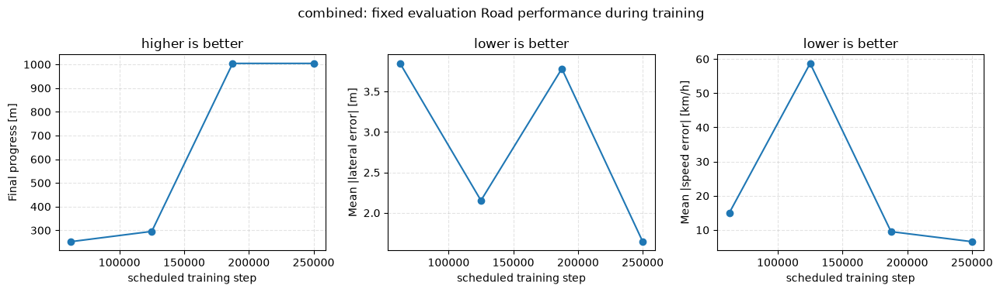

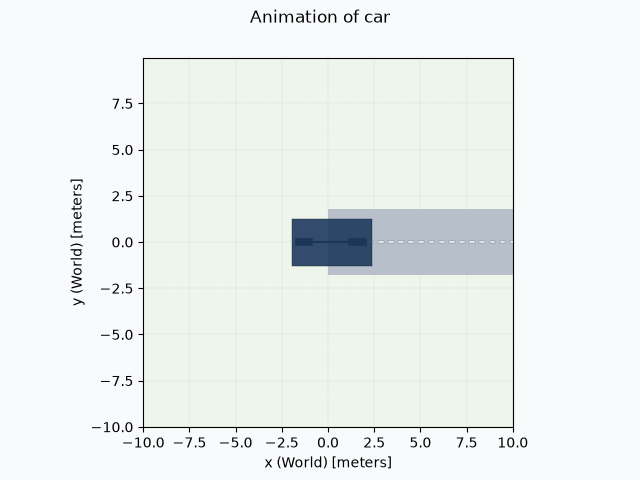

In [231]:
combined_reward_parameters = copy.deepcopy(SELECTED_REWARD_PARAMETERS)
combined_config = copy.deepcopy(STAGE_CONFIGS["combined"])
combined_config.reward.preset_parameters = copy.deepcopy(combined_reward_parameters)
combined_requested_snapshot = config_to_dict(combined_config)

combined_result = train(combined_config)

combined_run_dir = Path(combined_result.run_dir)
combined_resolved_snapshot = json.loads(
    Path(combined_result.resolved_config_path).read_text(encoding="utf-8")
)
combined_scheduled_evaluation_rows = read_scheduled_evaluation_rows(combined_run_dir)
combined_effective_reward = combined_resolved_snapshot["reward"]["effective"]

COMBINED_STAGE_SUMMARY = {
    "evaluation_scope": "scheduled fixed-Road evaluation",
    "requested_aggregate_transitions": combined_requested_snapshot["requested_total_environment_transitions"],
    "actual_aggregate_transitions": combined_result.actual_environment_transitions,
    "algorithm": combined_resolved_snapshot["algorithm"]["name"],
    "requested_action_interface": combined_requested_snapshot["env"]["action_interface"],
    "resolved_action_interface": combined_resolved_snapshot["environment"]["effective_action_interface"],
    "policy_observation_names": tuple(
        combined_resolved_snapshot["spaces"]["flat_observation_names"]
    ),
    "reward_preset": combined_effective_reward["preset_name"],
    "requested_reward_parameters": combined_requested_snapshot["reward"]["preset_parameters"],
    "effective_reward_parameters": combined_effective_reward["preset_parameters"],
    "fixed_evaluation_road_names": tuple(
        row["road_name"] for row in combined_scheduled_evaluation_rows
    ),
    **{
        f"mean_{metric_name}": mean_metric(combined_scheduled_evaluation_rows, metric_name)
        for metric_name in COMPARISON_METRIC_NAMES
    },
    "run_dir": combined_run_dir,
    "final_model_path": combined_result.final_model_path,
    "summary_path": combined_result.summary_path,
}
display_mapping(COMBINED_STAGE_SUMMARY, title="Combined-stage result")
COMBINED_LEARNING_HISTORY = display_learning_history(
    "combined", combined_run_dir, combined_scheduled_evaluation_rows
)
combined_animation_paths = display_run_animations(
    combined_run_dir, title="Optional combined-policy animations"
)


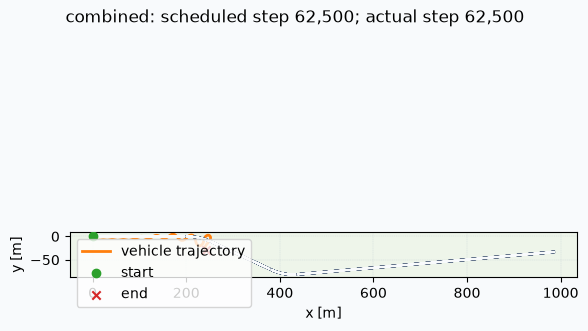

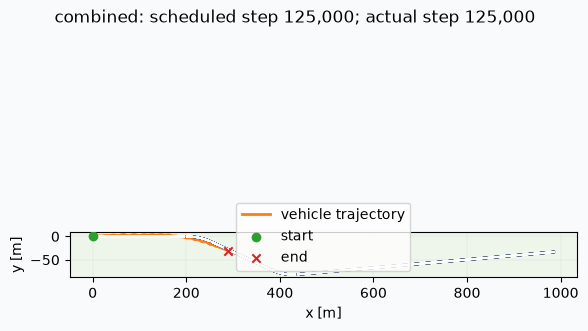

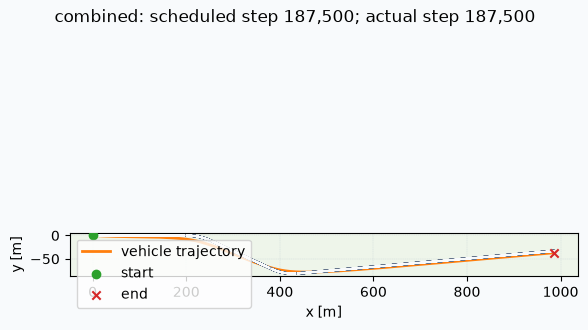

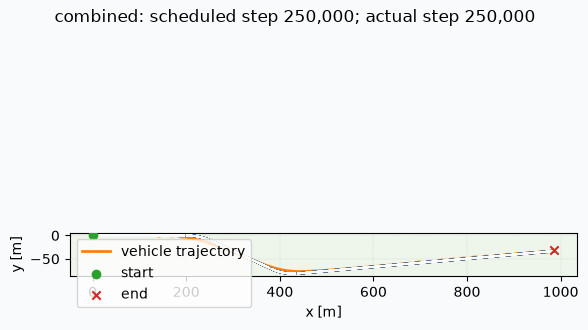

scheduled_step,actual_step,checkpoint_model,trajectory_plot,time_series_plot
62500,62500,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/models/model_at_evaluation_000062500.zip,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/plots/checkpoint_trajectory_at_000062500.png,—
125000,125000,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/models/model_at_evaluation_000125000.zip,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/plots/checkpoint_trajectory_at_000125000.png,—
187500,187500,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/models/model_at_evaluation_000187500.zip,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/plots/checkpoint_trajectory_at_000187500.png,—
250000,250000,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/models/model_at_evaluation_000250000.zip,notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/plots/checkpoint_trajectory_at_000250000.png,—


In [232]:
# Replays saved checkpoint models only; this cell does not retrain the policy.
COMBINED_CHECKPOINT_TRAJECTORIES = display_checkpoint_trajectories(
    "combined", combined_result, combined_scheduled_evaluation_rows
)


#### 3.4.4 Evaluation metrics

The assignment metric definitions come from [the performance-metrics notebook](./ad_gym_performance_metrics_and_uncertainty_2026_08_17.ipynb).


In [233]:
PERFORMANCE_METRICS_NOTEBOOK = Path(
    "ad_gym_performance_metrics_and_uncertainty_2026_08_17.ipynb"
)
if not PERFORMANCE_METRICS_NOTEBOOK.exists():
    PERFORMANCE_METRICS_NOTEBOOK = Path("notebooks") / PERFORMANCE_METRICS_NOTEBOOK
if not PERFORMANCE_METRICS_NOTEBOOK.exists():
    raise FileNotFoundError(PERFORMANCE_METRICS_NOTEBOOK)

PERFORMANCE_METRIC_CELL_IDS = (
    "metrics-metric-selection",
    "metrics-custom-metric",
    "metrics-metric-summary",
)
performance_metrics_notebook = json.loads(
    PERFORMANCE_METRICS_NOTEBOOK.read_text(encoding="utf-8")
)
performance_metric_cells = {
    cell.get("id"): cell
    for cell in performance_metrics_notebook["cells"]
    if cell.get("id") in PERFORMANCE_METRIC_CELL_IDS
}
missing_metric_cells = set(PERFORMANCE_METRIC_CELL_IDS) - set(
    performance_metric_cells
)
if missing_metric_cells:
    raise RuntimeError(
        f"Missing metric cells in {PERFORMANCE_METRICS_NOTEBOOK}: "
        f"{sorted(missing_metric_cells)}"
    )

for metric_cell_id in PERFORMANCE_METRIC_CELL_IDS:
    metric_cell_source = "".join(
        performance_metric_cells[metric_cell_id]["source"]
    )
    exec(
        compile(
            metric_cell_source,
            f"{PERFORMANCE_METRICS_NOTEBOOK}#{metric_cell_id}",
            "exec",
        ),
        globals(),
    )

RL_METRICS = metrics
print(f"RL metrics loaded from {PERFORMANCE_METRICS_NOTEBOOK}")


{'name': 'mean_abs_lateral_error_m', 'unit': 'm', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'mean_abs_speed_error_to_recommended_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'final_progress_m', 'unit': 'm', 'direction': 'bigger', 'required_fields': ('reference_line_progress_at_closest_point',), 'primary_aggregate': 'mean'}
{'name': 'fraction_outside_lateral_tolerance', 'unit': 'fraction', 'direction': 'smaller', 'required_fields': ('lateral_error_from_target_line',), 'primary_aggregate': 'mean'}
{'name': 'cumulative_overspeed_duration_s', 'unit': 's', 'direction': 'smaller', 'required_fields': ('time_in_seconds', 'vx', 'recommended_speed_at_closest_point'), 'primary_aggregate': 'mean'}
{'name': 'maximum_overspeed_kph', 'unit': 'km/h', 'direction': 'smaller', 'required_fields': ('vx', 'recommended_speed_at_clo

#### 3.4.5 Validate the saved policy

Completion of a training call does not establish that its saved artifact can be loaded and
evaluated independently. The next cells reopen the combined policy with
`load_model_and_config_for_evaluation` and run it on the fixed evaluation Road without using
live model objects from training.

The loader reconstructs the evaluation environment from the resolved configuration stored in
the run directory. One pass collects trajectory metrics. A second deterministic pass records
the contribution of every reward term at each step. The resulting trace supports the reward
analysis in the following section.


In [234]:
def collect_reward_term_rows(environment, policy, coefficients, reset_seed, n_steps):
    """Step a policy by hand and recompute every reward term, per step.

    `simulate_policy` gives metrics; this gives the reward breakdown behind them.
    Both drive the same environment from the same seed, so the two agree.
    """
    observation, info = environment.reset(seed=reset_seed)
    previous_ground_truth = environment.unwrapped.get_current_ground_truth()
    terminated = truncated = False
    reward_term_rows = []
    for step_index in range(n_steps):
        action = policy.compute_action(observation, info, terminated, truncated)
        (
            next_observation, base_reward, terminated, truncated, next_info,
        ) = environment.step(action)
        ground_truth = environment.unwrapped.get_current_ground_truth()
        context = RewardContext(
            observation=copy.deepcopy(next_observation),
            action=copy.deepcopy(action),
            base_reward=float(base_reward),
            terminated=bool(terminated),
            truncated=bool(truncated),
            info=copy.deepcopy(next_info),
            ground_truth=copy.deepcopy(ground_truth),
            previous_ground_truth=copy.deepcopy(previous_ground_truth),
        )
        reward_total, reward_terms = driving_reward(context, coefficients)
        termination_reasons = dict(next_info.get("termination_reasons", {}))
        completion_observed = bool(terminated and termination_reasons.get(
            "road_progress_completion_threshold_reached"
        ))
        lateral_termination_observed = bool(terminated and termination_reasons.get(
            "absolute_lateral_error_from_target_line_above_upper_bound"
        ))
        pure_truncation_observed = bool(truncated and not terminated)
        reward_term_rows.append({
            "step_index": step_index,
            "reward_total": float(reward_total),
            "terminated": bool(terminated),
            "truncated": bool(truncated),
            "completion_observed": completion_observed,
            "lateral_termination_observed": lateral_termination_observed,
            "pure_truncation_observed": pure_truncation_observed,
            "termination_reasons": termination_reasons,
            **{name: float(value) for name, value in reward_terms.items()},
        })
        observation, info = next_observation, next_info
        previous_ground_truth = ground_truth
        if terminated or truncated:
            break
    if not reward_term_rows:
        raise RuntimeError("combined reward diagnostic produced no steps")
    return reward_term_rows


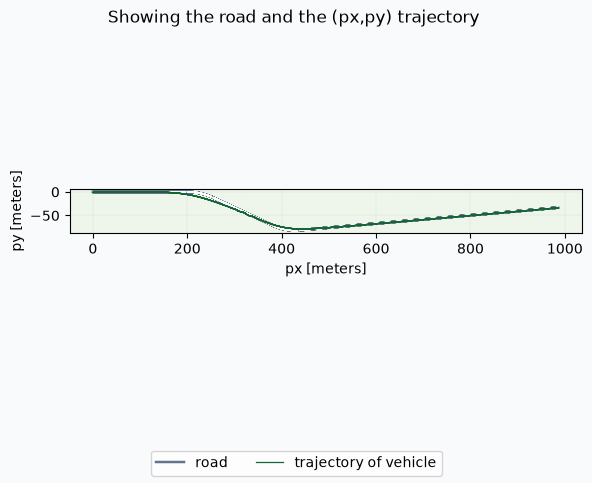

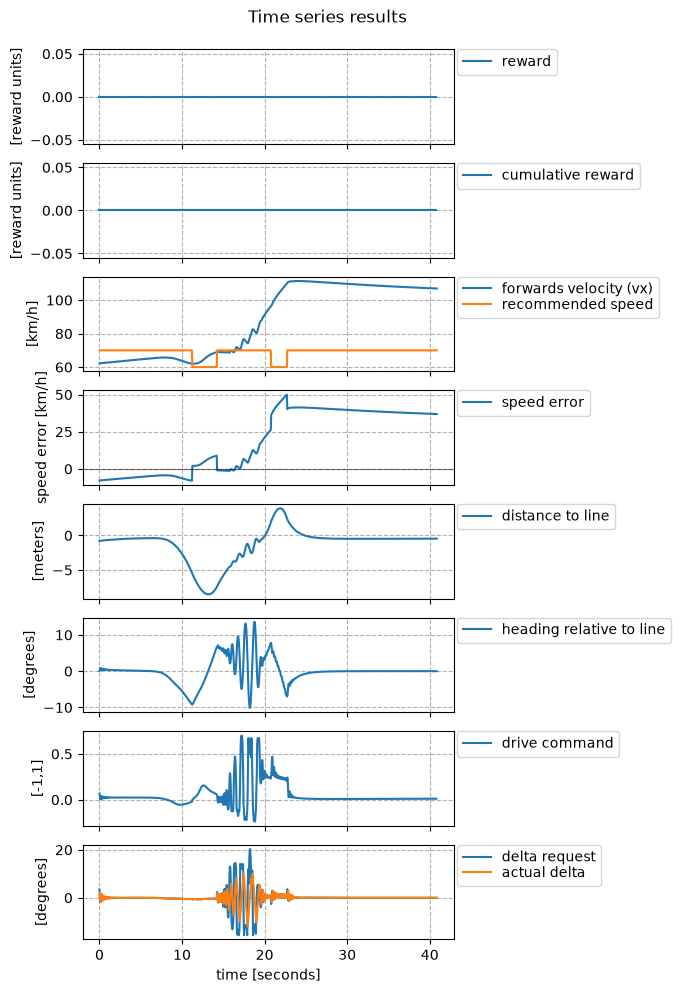

field,value
mean_abs_lateral_error_m,1.682
mean_abs_speed_error_to_recommended_kph,22.76
final_progress_m,1004
fraction_outside_lateral_tolerance,0.3533
cumulative_overspeed_duration_s,27.1
maximum_overspeed_kph,49.97
rms_longitudinal_jerk_mps3,7.316
rms_steering_request_rate_rad_per_s,0.724


field,value
snapshot_type,resolved
resolver_version,dreamgym-training-resolver-v3
snapshot_path,/Users/namanhtran/project/DRL_VS_MPC_COMPARISON/notebooks/notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/resolved_config.json
requested_config_digest,7ebdd18020a2ca3192d94a8e8c73585b9265f2deb437c87f4b1dc20b9ed96b5d


{'snapshot_type': 'resolved',
 'resolver_version': 'dreamgym-training-resolver-v3',
 'snapshot_path': '/Users/namanhtran/project/DRL_VS_MPC_COMPARISON/notebooks/notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/resolved_config.json',
 'requested_config_digest': '7ebdd18020a2ca3192d94a8e8c73585b9265f2deb437c87f4b1dc20b9ed96b5d'}

In [235]:
def run_combined_reload_evidence():
    """Reopen the saved combined policy and drive the fixed evaluation Road once.

    The loader is the only way the policy comes back: it reads the run's resolved
    snapshot, so the environment is rebuilt from the recorded public constructor
    rather than from anything still live in this notebook.
    """
    with load_model_and_config_for_evaluation(
        combined_result.final_model_path,
        explicit_config=combined_result.resolved_config_path,
    ) as combined_loaded:
        loaded_snapshot = combined_loaded.config.to_dict()
        environment_record = loaded_snapshot["environment"]
        evaluation_environment_kwargs = copy.deepcopy(
            environment_record["public_constructor_template"]
        )
        evaluation_environment_kwargs["road_spec"] = copy.deepcopy(
            loaded_snapshot["roads"]["fixed_evaluation_road_specs"][0]
        )
        combined_reload_environment = gym.make(
            "dreamgym/autonomous_driving_env", **evaluation_environment_kwargs
        )
        try:
            combined_reload_environment.unwrapped.set_tire_force_condition(
                environment_record["postconstruction_settings"]["tire_force_condition"]
            )
            policy = RLPolicy(combined_loaded.model)
            reset_seed = RL_SEEDS["fixed_road_environment_reset_seed"]
            time_series = simulate_policy(
                combined_reload_environment, MODE["evaluation_steps"], policy, seed=reset_seed
            )
            trajectory_figures = plot_simulation_results(
                combined_reload_environment,
                time_series,
                should_plot_reward=True,
                should_plot_speed_error=True,
            )
            trajectory_plot_paths = {}
            for plot_name, figure in trajectory_figures.items():
                display(figure)
                trajectory_plot_paths[plot_name] = save_figure(
                    figure, OUTPUT_ROOT / f"combined-final-{plot_name}.png"
                )
                plt.close(figure)
            return copy.deepcopy({
                "time_series": time_series,
                "metric_row": compute_autonomous_driving_metrics(time_series, RL_METRICS),
                "trajectory_plot_paths": trajectory_plot_paths,
                "reward_term_rows": collect_reward_term_rows(
                    combined_reload_environment,
                    policy,
                    REWARD_PARAMETERS["combined"],
                    reset_seed,
                    MODE["evaluation_steps"],
                ),
                "snapshot_type": loaded_snapshot["snapshot_type"],
                "resolver_version": loaded_snapshot["resolver_version"],
                "snapshot_path": str(combined_loaded.snapshot_path),
                "requested_config_digest": loaded_snapshot["requested_config_digest"],
            })
        finally:
            combined_reload_environment.close()

combined_reload_evidence = run_combined_reload_evidence()
combined_reload_time_series = combined_reload_evidence["time_series"]
combined_reload_metric_row = combined_reload_evidence["metric_row"]
combined_reload_artifact_identity = {
    "snapshot_type": combined_reload_evidence["snapshot_type"],
    "resolver_version": combined_reload_evidence["resolver_version"],
    "snapshot_path": combined_reload_evidence["snapshot_path"],
    "requested_config_digest": combined_reload_evidence["requested_config_digest"],
}
display_mapping(combined_reload_metric_row, title="Final combined-policy metrics")
display_mapping(
    combined_reload_artifact_identity, title="Reloaded policy artifact"
)


#### 3.4.6 Diagnose reward and driving-quality alignment

A positive return does not by itself establish successful driving. The next cells compare the
normal combined reward with completion, progress, direction, and episode-ending evidence from
the same deterministic evaluation rollout. The final Boolean is a diagnostic flag: a value of
`False` means that this criterion found no contradiction, not that the policy is proven safe or
generally successful.


In [236]:
WRONG_DIRECTION_FRACTION_LIMIT = 0.10

def summarize_reward_alignment(reward_rows):
    """Compare episode return with task-level evidence from one rollout."""
    if not reward_rows:
        raise ValueError("reward alignment requires at least one transition")
    episode_return = float(sum(row["reward_total"] for row in reward_rows))
    net_progress_m = float(sum(row["progress"] for row in reward_rows))
    wrong_direction_step_fraction = float(np.mean([
        row["progress"] < 0.0 for row in reward_rows
    ]))
    completion_observed = any(row["completion_observed"] for row in reward_rows)
    lateral_termination_observed = any(
        row["lateral_termination_observed"] for row in reward_rows
    )
    pure_truncation_observed = any(
        row["pure_truncation_observed"] for row in reward_rows
    )
    conditions_not_met = []
    if not completion_observed:
        conditions_not_met.append("Road completion not observed")
    if net_progress_m <= 0.0:
        conditions_not_met.append("net progress is not positive")
    if wrong_direction_step_fraction > WRONG_DIRECTION_FRACTION_LIMIT:
        conditions_not_met.append("wrong-direction fraction exceeds the limit")
    if lateral_termination_observed:
        conditions_not_met.append("lateral termination observed")
    if pure_truncation_observed:
        conditions_not_met.append("pure truncation observed")
    potential_reward_misalignment = bool(
        episode_return > 0.0 and conditions_not_met
    )
    return {
        "transitions_observed": len(reward_rows),
        "episode_return": episode_return,
        "completion_observed": completion_observed,
        "net_progress_m": net_progress_m,
        "wrong_direction_step_fraction": wrong_direction_step_fraction,
        "wrong_direction_fraction_limit": WRONG_DIRECTION_FRACTION_LIMIT,
        "lateral_termination_observed": lateral_termination_observed,
        "pure_truncation_observed": pure_truncation_observed,
        "episode_ended": any(row["terminated"] or row["truncated"] for row in reward_rows),
        "conditions_not_met": tuple(conditions_not_met),
        "potential_reward_misalignment": potential_reward_misalignment,
        "interpretation": (
            "positive return conflicts with at least one task-success condition"
            if potential_reward_misalignment
            else "no return-success contradiction under this diagnostic"
        ),
    }


In [237]:
combined_reward_term_rows = copy.deepcopy(
    combined_reload_evidence["reward_term_rows"]
)
combined_reward_alignment = summarize_reward_alignment(
    combined_reward_term_rows
)
display_mapping(
    combined_reward_alignment, title="Combined-policy episode diagnostic"
)
display_records(
    combined_reward_term_rows[:12],
    columns=(
        "step_index", "reward_total", "lane", "speed", "progress",
        "heading_gate", "completion_observed",
        "lateral_termination_observed", "pure_truncation_observed",
    ),
    title="Normal combined-reward decomposition: first 12 steps",
)
_ = display_mapping(
    combined_reload_artifact_identity, title="Evidence source"
)


field,value
transitions_observed,817
episode_return,1151
completion_observed,True
net_progress_m,1004
wrong_direction_step_fraction,0
wrong_direction_fraction_limit,0.1
lateral_termination_observed,False
pure_truncation_observed,False
episode_ended,True
conditions_not_met,[]


step_index,reward_total,lane,speed,progress,heading_gate,completion_observed,lateral_termination_observed,pure_truncation_observed
0,1.474,0.5563,0.3179,0.8643,1,False,False,False
1,1.488,0.5629,0.3192,0.8651,0.9999,False,False,False
2,1.498,0.5676,0.3192,0.8655,0.9999,False,False,False
3,1.499,0.5681,0.3192,0.8656,1,False,False,False
4,1.499,0.5681,0.32,0.8658,1,False,False,False
5,1.508,0.5717,0.3214,0.8663,1,False,False,False
6,1.518,0.5765,0.3221,0.8667,0.9999,False,False,False
7,1.523,0.5785,0.3222,0.867,1,False,False,False
8,1.524,0.579,0.3228,0.8672,1,False,False,False
9,1.53,0.5814,0.324,0.8676,1,False,False,False


field,value
snapshot_type,resolved
resolver_version,dreamgym-training-resolver-v3
snapshot_path,/Users/namanhtran/project/DRL_VS_MPC_COMPARISON/notebooks/notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123/resolved_config.json
requested_config_digest,7ebdd18020a2ca3192d94a8e8c73585b9265f2deb437c87f4b1dc20b9ed96b5d


### 3.4.7 PPO rollout tuning

The reward and observation set are fixed while PPO rollout size is varied
across 512, 1024, and 2048 transitions. The existing 1024-transition
baseline run is reused as the reference candidate.


In [238]:
if RUN_MODE == "full":
    PPO_ROLLOUT_SIZES = (512, 1024, 2048)
else:
    PPO_ROLLOUT_SIZES = (32, 64, 128)

REFERENCE_ROLLOUT_SIZE = MODE["rollout_transitions"]

PPO_STAGE_SETUP = copy.deepcopy(
    STAGE_SETUP["combined"]
)

# IMPORTANT: wipe stale experiment references
PPO_EXPERIMENTS = {}

print("PPO rollout sizes:", PPO_ROLLOUT_SIZES)
print("Reference rollout size:", REFERENCE_ROLLOUT_SIZE)

PPO rollout sizes: (512, 1024, 2048)
Reference rollout size: 1024


In [239]:
'''
select reward run already use the ref PPO rollout size
re-use it rather than training identical policy
'''

reference_candidate_name = (f'rollout_{REFERENCE_ROLLOUT_SIZE}')
PPO_EXPERIMENTS[reference_candidate_name] = {
    "candidate_name": reference_candidate_name,
    "rollout_transitions": REFERENCE_ROLLOUT_SIZE,
    "result": combined_result,
    "run_dir": Path(combined_result.run_dir),
    "requested_snapshot": copy.deepcopy(
        combined_requested_snapshot
    ),
    "resolved_snapshot": copy.deepcopy(
        combined_resolved_snapshot
    ),
    "scheduled_rows": copy.deepcopy(
        combined_scheduled_evaluation_rows
    ),
}

print(
    "Reusing existing PPO reference:",
    reference_candidate_name,
)
print(
    "Run directory:",
    PPO_EXPERIMENTS[
        reference_candidate_name
    ]["run_dir"],
)

# do not waste 250,000 transition training run on 1024


Reusing existing PPO reference: rollout_1024
Run directory: notebook_outputs/rl-reward-shaping-and-training/combined/rl-reward-shaping-combined_20260830-111123


In [240]:
def train_ppo_candidate(rollout_transitions):

    candidate_name = (
        f"rollout_{rollout_transitions}"
    )

    candidate_mode = copy.deepcopy(MODE)

    # THIS is the parameter being investigated.
    candidate_mode["rollout_transitions"] = (
        rollout_transitions
    )

    candidate_config = build_training_config(
        candidate_name,
        PPO_STAGE_SETUP,
        SELECTED_REWARD_PARAMETERS,
        candidate_mode,
        OUTPUT_ROOT,
    )

    requested_snapshot = config_to_dict(
        candidate_config
    )

    print("\n" + "=" * 60)
    print("Training PPO candidate:", candidate_name)

    print(
        "Requested rollout transitions:",
        requested_snapshot[
            "algorithm"
        ][
            "n_rollout_transitions_per_update"
        ],
    )

    result = train(
        copy.deepcopy(candidate_config)
    )

    run_directory = Path(
        result.run_dir
    )

    resolved_snapshot = json.loads(
        Path(
            result.resolved_config_path
        ).read_text(
            encoding="utf-8"
        )
    )

    scheduled_rows = (
        read_scheduled_evaluation_rows(
            run_directory
        )
    )

    return {
        "candidate_name": candidate_name,
        "rollout_transitions": rollout_transitions,
        "result": result,
        "run_dir": run_directory,
        "requested_snapshot": requested_snapshot,
        "resolved_snapshot": resolved_snapshot,
        "scheduled_rows": scheduled_rows,
    }

In [241]:
for rollout_transitions in PPO_ROLLOUT_SIZES:

    candidate_name = (
        f"rollout_{rollout_transitions}"
    )

    if candidate_name in PPO_EXPERIMENTS:
        print(
            "Skipping existing:",
            candidate_name,
        )
        continue

    PPO_EXPERIMENTS[
        candidate_name
    ] = train_ppo_candidate(
        rollout_transitions
    )


Training PPO candidate: rollout_512
Requested rollout transitions: 512
62500/250000 25.0% elapsed=00:00:11 eta=00:00:34
125000/250000 50.0% elapsed=00:00:23 eta=00:00:23
187500/250000 75.0% elapsed=00:00:34 eta=00:00:11
250000/250000 100.0% elapsed=00:00:46 eta=00:00:00
250368/250000 100.0% elapsed=00:00:46 eta=00:00:00
Skipping existing: rollout_1024

Training PPO candidate: rollout_2048
Requested rollout transitions: 2048
62500/250000 25.0% elapsed=00:00:10 eta=00:00:32
125000/250000 50.0% elapsed=00:00:22 eta=00:00:22
187500/250000 75.0% elapsed=00:00:33 eta=00:00:11
250000/250000 100.0% elapsed=00:00:45 eta=00:00:00
251904/250000 100.0% elapsed=00:00:45 eta=00:00:00


In [242]:
PPO_CONFIGURATION_ROWS = []

for candidate_name, experiment in (
    PPO_EXPERIMENTS.items()
):
    snapshot = experiment[
        "requested_snapshot"
    ]

    PPO_CONFIGURATION_ROWS.append({
        "candidate": candidate_name,
        "rollout_transitions": (
            experiment[
                "rollout_transitions"
            ]
        ),
        "requested_transitions": snapshot[
            "requested_total_environment_transitions"
        ],
        "n_envs": snapshot[
            "vectorization"
        ]["n_envs"],
        "n_epochs": snapshot[
            "algorithm"
        ]["hyperparameters"]["n_epochs"],
        "batch_size": snapshot[
            "algorithm"
        ]["hyperparameters"]["batch_size"],
        "reward_parameters": snapshot[
            "reward"
        ]["preset_parameters"],
    })

display_records(
    PPO_CONFIGURATION_ROWS,
    title="Controlled PPO rollout-size experiment",
)

candidate,rollout_transitions,requested_transitions,n_envs,n_epochs,batch_size,reward_parameters
rollout_1024,1024,250000,4,4,64,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"
rollout_512,512,250000,4,4,64,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"
rollout_2048,2048,250000,4,4,64,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"


({'candidate': 'rollout_1024',
  'rollout_transitions': 1024,
  'requested_transitions': 250000,
  'n_envs': 4,
  'n_epochs': 4,
  'batch_size': 64,
  'reward_parameters': {'k_lane': 2.0,
   'k_speed': 1.0,
   'k_progress': 0.05,
   'road_progress_completion_reward': 5.0,
   'absolute_lateral_error_from_target_line_termination_reward': -10.0,
   'truncation_without_termination_reward': -2.0}},
 {'candidate': 'rollout_512',
  'rollout_transitions': 512,
  'requested_transitions': 250000,
  'n_envs': 4,
  'n_epochs': 4,
  'batch_size': 64,
  'reward_parameters': {'k_lane': 2.0,
   'k_speed': 1.0,
   'k_progress': 0.05,
   'road_progress_completion_reward': 5.0,
   'absolute_lateral_error_from_target_line_termination_reward': -10.0,
   'truncation_without_termination_reward': -2.0}},
 {'candidate': 'rollout_2048',
  'rollout_transitions': 2048,
  'requested_transitions': 250000,
  'n_envs': 4,
  'n_epochs': 4,
  'batch_size': 64,
  'reward_parameters': {'k_lane': 2.0,
   'k_speed': 1.0,
 

In [243]:
"""
How quickly and smoothly PPO learned based on rollout sizes
"""
def checkpoint_metric_history(
    scheduled_rows,
    metric_name,
):
    grouped = {}

    for row in scheduled_rows:
        step = int(
            float(
                row[
                    "scheduled_evaluation_step"
                ]
            )
        )

        grouped.setdefault(
            step,
            [],
        ).append(
            float(row[metric_name])
        )

    steps = sorted(grouped)

    values = [
        float(
            np.mean(grouped[step])
        )
        for step in steps
    ]

    return steps, values


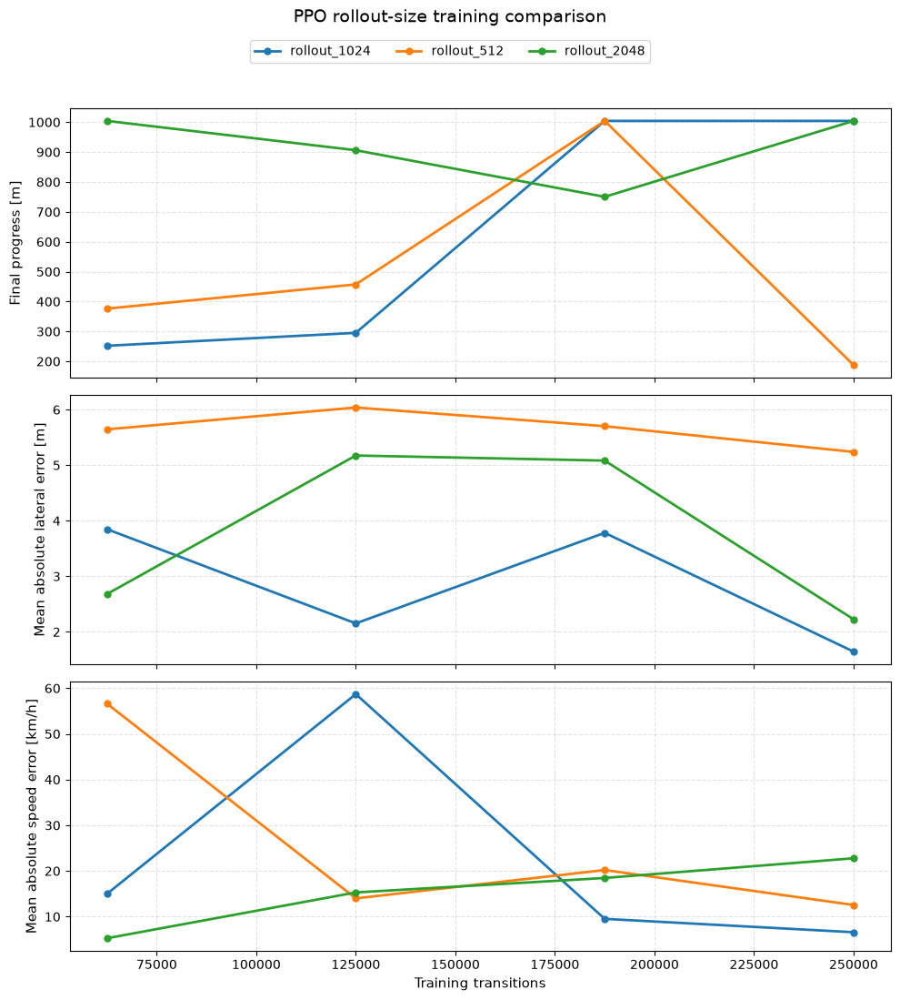

In [244]:
PPO_HISTORY_METRICS = (
    (
        "final_progress_m",
        "Final progress [m]",
    ),
    (
        "mean_abs_lateral_error_m",
        "Mean absolute lateral error [m]",
    ),
    (
        "mean_abs_speed_error_to_recommended_kph",
        "Mean absolute speed error [km/h]",
    ),
)

ppo_history_figure, ppo_history_axes = plt.subplots(
    3,
    1,
    figsize=(10, 11),
    sharex=True,
)

try:
    for axis, (
        metric_name,
        metric_label,
    ) in zip(
        ppo_history_axes,
        PPO_HISTORY_METRICS,
        strict=True,
    ):

        for (
            candidate_name,
            experiment,
        ) in PPO_EXPERIMENTS.items():

            steps, values = checkpoint_metric_history(
                experiment["scheduled_rows"],
                metric_name,
            )

            axis.plot(
                steps,
                values,
                marker="o",
                linewidth=2,
                markersize=5,
                label=candidate_name,
            )

        axis.set_ylabel(
            metric_label,
            fontsize=11,
        )

        axis.grid(
            True,
            linestyle="--",
            alpha=0.35,
        )

        axis.tick_params(
            axis="both",
            labelsize=10,
        )

    ppo_history_axes[-1].set_xlabel(
        "Training transitions",
        fontsize=11,
    )

    handles, labels = (
        ppo_history_axes[0]
        .get_legend_handles_labels()
    )

    ppo_history_figure.legend(
        handles,
        labels,
        loc="upper center",
        ncol=len(labels),
        bbox_to_anchor=(0.5, 0.97),
        frameon=True,
    )

    ppo_history_figure.suptitle(
        "PPO rollout-size training comparison",
        fontsize=14,
        y=0.995,
    )

    ppo_history_figure.tight_layout(
        rect=(0, 0, 1, 0.94)
    )

    display(
        ppo_history_figure
    )

finally:
    plt.close(
        ppo_history_figure
    )

#### 3.4.7.1 Client-metric evaluation


In [245]:
def rollout_flag(time_series, key):
    value = np.asarray(
        time_series.get(key, False)
    )

    if value.size == 0:
        return False

    return bool(np.any(value))


def evaluate_saved_ppo_candidate(experiment):
    result = experiment["result"]

    with load_model_and_config_for_evaluation(
        result.final_model_path,
        explicit_config=result.resolved_config_path,
    ) as loaded:

        snapshot = loaded.config.to_dict()

        environment_record = snapshot["environment"]

        environment_kwargs = copy.deepcopy(
            environment_record[
                "public_constructor_template"
            ]
        )

        # All PPO candidates use the same held-out
        # fixed evaluation road.
        environment_kwargs["road_spec"] = copy.deepcopy(
            snapshot[
                "roads"
            ][
                "fixed_evaluation_road_specs"
            ][0]
        )

        environment = gym.make(
            "dreamgym/autonomous_driving_env",
            **environment_kwargs,
        )

        try:
            environment.unwrapped.set_tire_force_condition(
                environment_record[
                    "postconstruction_settings"
                ][
                    "tire_force_condition"
                ]
            )

            policy = RLPolicy(
                loaded.model
            )

            time_series = simulate_policy(
                environment,
                MODE["evaluation_steps"],
                policy,
                seed=RL_SEEDS[
                    "fixed_road_environment_reset_seed"
                ],
            )

            metric_values = (
                compute_autonomous_driving_metrics(
                    time_series,
                    RL_METRICS,
                )
            )

        finally:
            environment.close()

    resolved_algorithm = snapshot["algorithm"]

    requested_rollout = resolved_algorithm[
        "requested_n_rollout_transitions_per_update"
    ]

    sb3_n_steps = resolved_algorithm[
        "constructor_kwargs"
    ]["n_steps"]

    terminated = rollout_flag(
        time_series,
        "terminated",
    )

    truncated = rollout_flag(
        time_series,
        "truncated",
    )

    return {
        "candidate": experiment[
            "candidate_name"
        ],

        # What our experiment intended to change
        "rollout_transitions": experiment[
            "rollout_transitions"
        ],

        # What Dream Gym actually resolved
        "resolved_rollout_transitions": (
            requested_rollout
        ),

        # SB3 PPO per-environment rollout length
        "sb3_n_steps": sb3_n_steps,

        "requested_transitions": experiment[
            "requested_snapshot"
        ][
            "requested_total_environment_transitions"
        ],

        "actual_transitions": (
            result.actual_environment_transitions
        ),

        "terminated": terminated,
        "truncated": truncated,

        **{
            metric_name: float(metric_value)
            for (
                metric_name,
                metric_value,
            ) in metric_values.items()
        },
    }

In [246]:
PPO_FINAL_EVALUATION_ROWS = tuple(
    evaluate_saved_ppo_candidate(
        experiment
    )
    for experiment in (
        PPO_EXPERIMENTS.values()
    )
)

PPO_FINAL_EVALUATION_ROWS = tuple(
    sorted(
        PPO_FINAL_EVALUATION_ROWS,
        key=lambda row: (
            row["rollout_transitions"]
        ),
    )
)

display_records(
    PPO_FINAL_EVALUATION_ROWS,
    title=(
        "PPO rollout-size held-out "
        "evaluation"
    ),
)

candidate,rollout_transitions,resolved_rollout_transitions,sb3_n_steps,requested_transitions,actual_transitions,terminated,truncated,mean_abs_lateral_error_m,mean_abs_speed_error_to_recommended_kph,final_progress_m,fraction_outside_lateral_tolerance,cumulative_overspeed_duration_s,maximum_overspeed_kph,rms_longitudinal_jerk_mps3,rms_steering_request_rate_rad_per_s
rollout_512,512,512,128,250000,250368,True,False,5.632,16.02,204.2,0.9528,9.2,37.23,31.48,3.928
rollout_1024,1024,1024,256,250000,250880,True,False,1.682,22.76,1004,0.3533,27.1,49.97,7.316,0.724
rollout_2048,2048,2048,512,250000,251904,True,False,2.097,15.89,1004,0.7219,24.7,29.97,17.96,2.678


({'candidate': 'rollout_512',
  'rollout_transitions': 512,
  'resolved_rollout_transitions': 512,
  'sb3_n_steps': 128,
  'requested_transitions': 250000,
  'actual_transitions': 250368,
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 5.631578966353598,
  'mean_abs_speed_error_to_recommended_kph': 16.0242274626246,
  'final_progress_m': 204.2482452392578,
  'fraction_outside_lateral_tolerance': 0.9528301886792453,
  'cumulative_overspeed_duration_s': 9.199999999999477,
  'maximum_overspeed_kph': 37.22998809814453,
  'rms_longitudinal_jerk_mps3': 31.475040730240913,
  'rms_steering_request_rate_rad_per_s': 3.9279039046666746},
 {'candidate': 'rollout_1024',
  'rollout_transitions': 1024,
  'resolved_rollout_transitions': 1024,
  'sb3_n_steps': 256,
  'requested_transitions': 250000,
  'actual_transitions': 250880,
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 1.6822221794474215,
  'mean_abs_speed_error_to_recommended_kph': 22.756300

In [247]:
SELECTED_PPO_ROLLOUT_TRANSITIONS = 1024

FINAL_RL_MODE = copy.deepcopy(MODE)

FINAL_RL_MODE[
    "rollout_transitions"
] = SELECTED_PPO_ROLLOUT_TRANSITIONS


### 3.4.8 Baseline vs speed-change lookahead

This is a controlled observation experiment. The candidate is identical to
the selected baseline except that it receives information about the next
recommended-speed change.

- Baseline: speed-change lookahead is `False`.
- Candidate: speed-change lookahead is `True`.
- Reward, PPO rollout size, target-line preview, and evaluation Road are unchanged.


In [248]:
SPEED_LOOKAHEAD_STAGE = copy.deepcopy(
    STAGE_SETUP["combined"]
)

speed_lookahead_config = build_training_config(
    "speed_lookahead",
    SPEED_LOOKAHEAD_STAGE,
    SELECTED_REWARD_PARAMETERS,
    FINAL_RL_MODE,
    OUTPUT_ROOT,
    include_next_speed_change_observations=True,
)

baseline_config_snapshot = config_to_dict(
    combined_config
)

lookahead_config_snapshot = config_to_dict(
    speed_lookahead_config
)

LOOKAHEAD_EXPERIMENT_SETUP = {
    "baseline_speed_lookahead": (
        baseline_config_snapshot[
            "env"
        ][
            "include_next_speed_change_observations"
        ]
    ),
    "candidate_speed_lookahead": (
        lookahead_config_snapshot[
            "env"
        ][
            "include_next_speed_change_observations"
        ]
    ),
    "target_line_distance_m": (
        lookahead_config_snapshot[
            "env"
        ][
            "target_line_lookahead_distance_m"
        ]
    ),
    "target_line_points": (
        lookahead_config_snapshot[
            "env"
        ][
            "target_line_lookahead_point_count"
        ]
    ),
    "rollout_transitions": (
        lookahead_config_snapshot[
            "algorithm"
        ][
            "n_rollout_transitions_per_update"
        ]
    ),
    "reward_parameters": (
        lookahead_config_snapshot[
            "reward"
        ][
            "preset_parameters"
        ]
    ),
}

if LOOKAHEAD_EXPERIMENT_SETUP["baseline_speed_lookahead"] is not False:
    raise AssertionError("The baseline must keep speed-change lookahead disabled.")
if LOOKAHEAD_EXPERIMENT_SETUP["candidate_speed_lookahead"] is not True:
    raise AssertionError("The candidate must enable speed-change lookahead.")

display_mapping(
    LOOKAHEAD_EXPERIMENT_SETUP,
    title="Baseline vs speed-lookahead experiment setup",
)


field,value
baseline_speed_lookahead,False
candidate_speed_lookahead,True
target_line_distance_m,100
target_line_points,10
rollout_transitions,1024
reward_parameters,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"


{'baseline_speed_lookahead': False,
 'candidate_speed_lookahead': True,
 'target_line_distance_m': 100.0,
 'target_line_points': 10,
 'rollout_transitions': 1024,
 'reward_parameters': {'k_lane': 2.0,
  'k_speed': 1.0,
  'k_progress': 0.05,
  'road_progress_completion_reward': 5.0,
  'absolute_lateral_error_from_target_line_termination_reward': -10.0,
  'truncation_without_termination_reward': -2.0}}

In [249]:
speed_lookahead_result = train(
    speed_lookahead_config
)


62500/250000 25.0% elapsed=00:00:11 eta=00:00:34
125000/250000 50.0% elapsed=00:00:23 eta=00:00:23
187500/250000 75.0% elapsed=00:00:35 eta=00:00:11
250000/250000 100.0% elapsed=00:00:47 eta=00:00:00
250880/250000 100.0% elapsed=00:00:47 eta=00:00:00


scheduled_step,actual_step,road,final_progress_m,mean_abs_lateral_error_m,mean_abs_speed_error_kph,terminated,truncated
62500,62500,fixed_0,1004,2.819,16.29,True,False
125000,125000,fixed_0,559.6,7.382,26.2,True,False
187500,187500,fixed_0,403.6,2.369,53.04,False,False
250000,250000,fixed_0,249.5,6.201,8.517,True,False


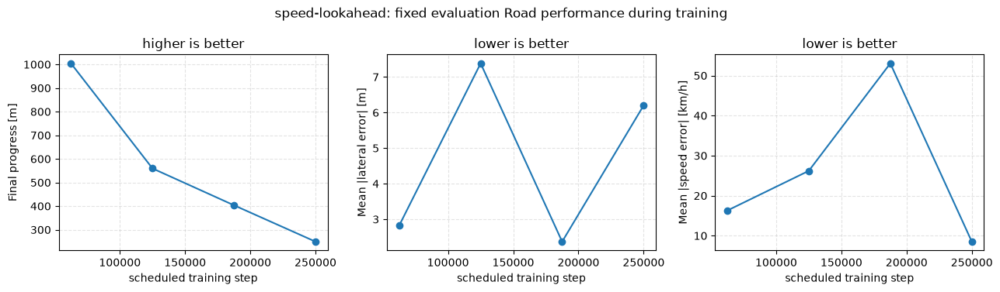

In [250]:
speed_lookahead_run_dir = Path(
    speed_lookahead_result.run_dir
)

speed_lookahead_requested_snapshot = config_to_dict(
    speed_lookahead_config
)

speed_lookahead_resolved_snapshot = json.loads(
    Path(
        speed_lookahead_result.resolved_config_path
    ).read_text(
        encoding="utf-8"
    )
)

speed_lookahead_scheduled_rows = (
    read_scheduled_evaluation_rows(
        speed_lookahead_run_dir
    )
)

SPEED_LOOKAHEAD_LEARNING_HISTORY = (
    display_learning_history(
        "speed-lookahead",
        speed_lookahead_run_dir,
        speed_lookahead_scheduled_rows,
    )
)


In [251]:
# ------------------------------------------------------------
# Full client-metric evaluation of every speed-lookahead checkpoint
# ------------------------------------------------------------

def evaluate_saved_checkpoint_client_metrics(
    checkpoint_path,
    resolved_config_path,
    candidate_name,
):
    with load_model_and_config_for_evaluation(
        checkpoint_path,
        explicit_config=resolved_config_path,
    ) as loaded:

        snapshot = loaded.config.to_dict()

        environment_record = snapshot[
            "environment"
        ]

        environment_kwargs = copy.deepcopy(
            environment_record[
                "public_constructor_template"
            ]
        )

        # Same held-out fixed evaluation road for every checkpoint.
        environment_kwargs["road_spec"] = copy.deepcopy(
            snapshot[
                "roads"
            ][
                "fixed_evaluation_road_specs"
            ][0]
        )

        environment = gym.make(
            "dreamgym/autonomous_driving_env",
            **environment_kwargs,
        )

        try:
            environment.unwrapped.set_tire_force_condition(
                environment_record[
                    "postconstruction_settings"
                ][
                    "tire_force_condition"
                ]
            )

            policy = RLPolicy(
                loaded.model
            )

            time_series = simulate_policy(
                environment,
                MODE["evaluation_steps"],
                policy,
                seed=RL_SEEDS[
                    "fixed_road_environment_reset_seed"
                ],
            )

            metric_values = (
                compute_autonomous_driving_metrics(
                    time_series,
                    RL_METRICS,
                )
            )

        finally:
            environment.close()

    return {
        "candidate": candidate_name,

        "terminated": rollout_flag(
            time_series,
            "terminated",
        ),

        "truncated": rollout_flag(
            time_series,
            "truncated",
        ),

        **{
            metric_name: float(metric_value)
            for metric_name, metric_value
            in metric_values.items()
        },
    }

speed_lookahead_checkpoint_paths = tuple(
    sorted(
        speed_lookahead_run_dir.glob(
            "models/model_at_evaluation_*.zip"
        )
    )
)

SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS = []

for checkpoint_path in speed_lookahead_checkpoint_paths:
    checkpoint_step = int(
        checkpoint_path.stem.rsplit("_", 1)[-1]
    )
    row = evaluate_saved_checkpoint_client_metrics(
        checkpoint_path,
        speed_lookahead_result.resolved_config_path,
        "speed_lookahead_" + str(checkpoint_step),
    )
    row["checkpoint_step"] = checkpoint_step
    SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS.append(row)

SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS = tuple(
    sorted(
        SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS,
        key=lambda row: row["checkpoint_step"],
    )
)

CLIENT_BENCHMARK_COLUMNS = (
    "candidate",
    "checkpoint_step",
    "final_progress_m",
    "cumulative_overspeed_duration_s",
    "maximum_overspeed_kph",
    "mean_abs_speed_error_to_recommended_kph",
    "rms_longitudinal_jerk_mps3",
    "mean_abs_lateral_error_m",
    "fraction_outside_lateral_tolerance",
    "rms_steering_request_rate_rad_per_s",
    "terminated",
    "truncated",
)

LOOKAHEAD_CHECKPOINT_COLUMNS = (
    "candidate",
    "checkpoint_step",
    "final_progress_m",
    "mean_abs_lateral_error_m",
    "mean_abs_speed_error_to_recommended_kph",
    "terminated",
    "truncated",
)

display_records(
    SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS,
    columns=LOOKAHEAD_CHECKPOINT_COLUMNS,
    title="Speed-lookahead checkpoint overview",
)


candidate,checkpoint_step,final_progress_m,mean_abs_lateral_error_m,mean_abs_speed_error_to_recommended_kph,terminated,truncated
speed_lookahead_62500,62500,1004,2.882,13.48,True,False
speed_lookahead_125000,125000,552.5,7.237,25.16,True,False
speed_lookahead_187500,187500,388.1,3.056,58.54,False,False
speed_lookahead_250000,250000,259.1,6.205,7.611,True,False


({'candidate': 'speed_lookahead_62500',
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 2.8821550784647623,
  'mean_abs_speed_error_to_recommended_kph': 13.48230277405815,
  'final_progress_m': 1004.319091796875,
  'fraction_outside_lateral_tolerance': 0.7232845894263217,
  'cumulative_overspeed_duration_s': 37.29999999999788,
  'maximum_overspeed_kph': 42.9649543762207,
  'rms_longitudinal_jerk_mps3': 2.371111932006206,
  'rms_steering_request_rate_rad_per_s': 0.9527489947733341,
  'checkpoint_step': 62500},
 {'candidate': 'speed_lookahead_125000',
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 7.237367097317159,
  'mean_abs_speed_error_to_recommended_kph': 25.156771267248082,
  'final_progress_m': 552.4834594726562,
  'fraction_outside_lateral_tolerance': 0.9273570324574961,
  'cumulative_overspeed_duration_s': 15.29999999999913,
  'maximum_overspeed_kph': 40.842979431152344,
  'rms_longitudinal_jerk_mps3': 3.9377951370205757,
  'r

In [252]:
BASELINE_PROGRESS_M = float(
    combined_reload_metric_row[
        "final_progress_m"
    ]
)

COMPLETION_THRESHOLD_M = (
    0.99 * BASELINE_PROGRESS_M
)

COMPLETING_LOOKAHEAD_ROWS = tuple(
    row
    for row in SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS
    if float(
        row["final_progress_m"]
    ) >= COMPLETION_THRESHOLD_M
)

display_records(
    COMPLETING_LOOKAHEAD_ROWS,
    columns=CLIENT_BENCHMARK_COLUMNS,
    title="Completing speed-lookahead checkpoints only",
)


candidate,checkpoint_step,final_progress_m,cumulative_overspeed_duration_s,maximum_overspeed_kph,mean_abs_speed_error_to_recommended_kph,rms_longitudinal_jerk_mps3,mean_abs_lateral_error_m,fraction_outside_lateral_tolerance,rms_steering_request_rate_rad_per_s,terminated,truncated
speed_lookahead_62500,62500,1004,37.3,42.96,13.48,2.371,2.882,0.7233,0.9527,True,False


({'candidate': 'speed_lookahead_62500',
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 2.8821550784647623,
  'mean_abs_speed_error_to_recommended_kph': 13.48230277405815,
  'final_progress_m': 1004.319091796875,
  'fraction_outside_lateral_tolerance': 0.7232845894263217,
  'cumulative_overspeed_duration_s': 37.29999999999788,
  'maximum_overspeed_kph': 42.9649543762207,
  'rms_longitudinal_jerk_mps3': 2.371111932006206,
  'rms_steering_request_rate_rad_per_s': 0.9527489947733341,
  'checkpoint_step': 62500},)

In [253]:
BASELINE_CLIENT_BENCHMARK_ROW = {
    "candidate": "baseline_no_speed_lookahead",
    "checkpoint_step": 250_000,
    "terminated": rollout_flag(
        combined_reload_time_series,
        "terminated",
    ),
    "truncated": rollout_flag(
        combined_reload_time_series,
        "truncated",
    ),
    **{
        metric_name: float(metric_value)
        for metric_name, metric_value
        in combined_reload_metric_row.items()
    },
}

BASELINE_VS_LOOKAHEAD_ROWS = (
    BASELINE_CLIENT_BENCHMARK_ROW,
    *COMPLETING_LOOKAHEAD_ROWS,
)

display_records(
    BASELINE_VS_LOOKAHEAD_ROWS,
    columns=CLIENT_BENCHMARK_COLUMNS,
    title="Baseline vs completing speed-lookahead policies",
)


candidate,checkpoint_step,final_progress_m,cumulative_overspeed_duration_s,maximum_overspeed_kph,mean_abs_speed_error_to_recommended_kph,rms_longitudinal_jerk_mps3,mean_abs_lateral_error_m,fraction_outside_lateral_tolerance,rms_steering_request_rate_rad_per_s,terminated,truncated
baseline_no_speed_lookahead,250000,1004,27.1,49.97,22.76,7.316,1.682,0.3533,0.724,True,False
speed_lookahead_62500,62500,1004,37.3,42.96,13.48,2.371,2.882,0.7233,0.9527,True,False


({'candidate': 'baseline_no_speed_lookahead',
  'checkpoint_step': 250000,
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 1.6822221794474215,
  'mean_abs_speed_error_to_recommended_kph': 22.756300575983847,
  'final_progress_m': 1004.319091796875,
  'fraction_outside_lateral_tolerance': 0.3533007334963325,
  'cumulative_overspeed_duration_s': 27.09999999999846,
  'maximum_overspeed_kph': 49.96647262573242,
  'rms_longitudinal_jerk_mps3': 7.316152197174156,
  'rms_steering_request_rate_rad_per_s': 0.7240276317601592},
 {'candidate': 'speed_lookahead_62500',
  'terminated': True,
  'truncated': False,
  'mean_abs_lateral_error_m': 2.8821550784647623,
  'mean_abs_speed_error_to_recommended_kph': 13.48230277405815,
  'final_progress_m': 1004.319091796875,
  'fraction_outside_lateral_tolerance': 0.7232845894263217,
  'cumulative_overspeed_duration_s': 37.29999999999788,
  'maximum_overspeed_kph': 42.9649543762207,
  'rms_longitudinal_jerk_mps3': 2.371111932006206,

In [254]:
if not COMPLETING_LOOKAHEAD_ROWS:
    raise RuntimeError(
        "No speed-lookahead checkpoint completed the evaluation road."
    )

BEST_SPEED_TRACKING_LOOKAHEAD_ROW = min(
    COMPLETING_LOOKAHEAD_ROWS,
    key=lambda row: float(
        row[
            "mean_abs_speed_error_to_recommended_kph"
        ]
    ),
)

DIRECT_COMPARISON_METRICS = (
    ("Final progress", "final_progress_m", "higher"),
    ("Overspeed duration", "cumulative_overspeed_duration_s", "lower"),
    ("Maximum overspeed", "maximum_overspeed_kph", "lower"),
    ("Speed MAE", "mean_abs_speed_error_to_recommended_kph", "lower"),
    ("RMS longitudinal jerk", "rms_longitudinal_jerk_mps3", "lower"),
    ("Lateral MAE", "mean_abs_lateral_error_m", "lower"),
    ("Outside lateral tolerance", "fraction_outside_lateral_tolerance", "lower"),
    ("RMS steering request rate", "rms_steering_request_rate_rad_per_s", "lower"),
)

BASELINE_VS_LOOKAHEAD_COMPARISON = []

for metric_label, metric_name, preferred_direction in DIRECT_COMPARISON_METRICS:
    baseline_value = float(
        BASELINE_CLIENT_BENCHMARK_ROW[metric_name]
    )
    lookahead_value = float(
        BEST_SPEED_TRACKING_LOOKAHEAD_ROW[metric_name]
    )
    difference = lookahead_value - baseline_value

    if np.isclose(baseline_value, lookahead_value):
        better = "tie"
    elif preferred_direction == "lower":
        better = "lookahead" if lookahead_value < baseline_value else "baseline"
    else:
        better = "lookahead" if lookahead_value > baseline_value else "baseline"

    BASELINE_VS_LOOKAHEAD_COMPARISON.append({
        "metric": metric_label,
        "baseline": baseline_value,
        "speed_lookahead": lookahead_value,
        "lookahead_minus_baseline": difference,
        "better": better,
    })

display_records(
    BASELINE_VS_LOOKAHEAD_COMPARISON,
    columns=(
        "metric",
        "baseline",
        "speed_lookahead",
        "lookahead_minus_baseline",
        "better",
    ),
    title="Direct baseline vs speed-lookahead comparison",
)


metric,baseline,speed_lookahead,lookahead_minus_baseline,better
Final progress,1004,1004,0,tie
Overspeed duration,27.1,37.3,10.2,baseline
Maximum overspeed,49.97,42.96,-7.002,lookahead
Speed MAE,22.76,13.48,-9.274,lookahead
RMS longitudinal jerk,7.316,2.371,-4.945,lookahead
Lateral MAE,1.682,2.882,1.2,baseline
Outside lateral tolerance,0.3533,0.7233,0.37,baseline
RMS steering request rate,0.724,0.9527,0.2287,baseline


({'metric': 'Final progress',
  'baseline': 1004.319091796875,
  'speed_lookahead': 1004.319091796875,
  'lookahead_minus_baseline': 0.0,
  'better': 'tie'},
 {'metric': 'Overspeed duration',
  'baseline': 27.09999999999846,
  'speed_lookahead': 37.29999999999788,
  'lookahead_minus_baseline': 10.19999999999942,
  'better': 'baseline'},
 {'metric': 'Maximum overspeed',
  'baseline': 49.96647262573242,
  'speed_lookahead': 42.9649543762207,
  'lookahead_minus_baseline': -7.001518249511719,
  'better': 'lookahead'},
 {'metric': 'Speed MAE',
  'baseline': 22.756300575983847,
  'speed_lookahead': 13.48230277405815,
  'lookahead_minus_baseline': -9.273997801925697,
  'better': 'lookahead'},
 {'metric': 'RMS longitudinal jerk',
  'baseline': 7.316152197174156,
  'speed_lookahead': 2.371111932006206,
  'lookahead_minus_baseline': -4.94504026516795,
  'better': 'lookahead'},
 {'metric': 'Lateral MAE',
  'baseline': 1.6822221794474215,
  'speed_lookahead': 2.8821550784647623,
  'lookahead_minus

### 3.4.9 DRL design decision

The speed-change observation experiment produced a clear trade-off.

Advance information about the next recommended-speed change improved
several longitudinal-control measures for a completing checkpoint,
including recommended-speed tracking, peak overspeed, and longitudinal
smoothness.

However, the same policy showed substantially worse lateral tracking
and steering smoothness than the baseline policy.

Therefore, speed-change lookahead was retained as a promising design
direction but was not selected for the final DRL policy because the
longitudinal improvements did not compensate for the degradation in
lateral control.

The selected DRL policy therefore retains the baseline observation set,
PPO rollout size of 1024 transitions, the selected combined reward,
100 m target-line lookahead with 10 points, and the default PPO learning
rate.


### 3.5 Domain-randomized training - Stage 5

The second policy trains on a newly generated Road at every reset, using the same reward, action interface, and transition budget as the fixed-Road policy.


#### 3.5.1 Training Road distribution

The training and in-distribution evaluation use the same generation support. The out-of-distribution stress test extends beyond it.


In [255]:
TRAINING_RANDOM_ROAD_GENERATION = {
    "element_count_range": {"lower": 8, "upper": 10},
    "straight_element_probability": 0.55,
    "straight": {"length_range_m": {"lower": 80.0, "upper": 150.0}},
    "circular_arc": {
        "radius_range_m": {"lower": 180.0, "upper": 320.0},
        "sweep_angle_range_deg": {"lower": 20.0, "upper": 30.0},
    },
    "speed_limit_range_kph": {"lower": 50.0, "upper": 80.0},
    "first_element": {
        "require_straight": True,
        "straight_length_range_m": {"lower": 250.0, "upper": 300.0},
    },
    "initial_cross_section": {
        "reference_line_role": "lane_center",
        "reference_lane_width_range_m": {"lower": 3.6, "upper": 3.6},
    },
    "active_lane_minimum_width_m": 0.05,
}
IN_DISTRIBUTION_EVALUATION_ROAD_GENERATION = copy.deepcopy(
    TRAINING_RANDOM_ROAD_GENERATION
)
OOD_STRESS_ROAD_GENERATION = {
    "element_count_range": {"lower": 10, "upper": 12},
    "straight_element_probability": 0.45,
    "straight": {"length_range_m": {"lower": 70.0, "upper": 170.0}},
    "circular_arc": {
        "radius_range_m": {"lower": 120.0, "upper": 280.0},
        "sweep_angle_range_deg": {"lower": 24.0, "upper": 40.0},
    },
    "speed_limit_range_kph": {"lower": 45.0, "upper": 90.0},
    "first_element": {
        "require_straight": True,
        "straight_length_range_m": {"lower": 200.0, "upper": 240.0},
    },
    "initial_cross_section": {
        "reference_line_role": "lane_center",
        "reference_lane_width_range_m": {"lower": 3.6, "upper": 3.6},
    },
    "active_lane_minimum_width_m": 0.05,
}
ROAD_GENERATION_FIELDS = (
    "element_count_range",
    "straight_element_probability",
    "straight",
    "circular_arc",
    "speed_limit_range_kph",
    "first_element",
    "initial_cross_section",
    "active_lane_minimum_width_m",
)


#### 3.5.2 Train and evaluate the randomized policy


In [256]:
STAGE_SETUP["domain_randomized"] = {
    "action": "full",
    "lane_keep": False,
    "cruise": False,
    "assistance": "none",
    "transition_key": "domain_randomized_transitions",
    "randomized": True,
    "save_final_model": True,
    "save_checkpoint_models": True,
    "save_checkpoint_plots": True,
    "animate_checkpoints": False,
    "animate_final": GENERATE_DOMAIN_RANDOMIZED_FINAL_GIF,
}
STAGE_CONFIGS["domain_randomized"] = build_training_config(
    "domain_randomized",
    STAGE_SETUP["domain_randomized"],
    SELECTED_REWARD_PARAMETERS,
    FINAL_RL_MODE,
    OUTPUT_ROOT,
    training_random_road_generation=TRAINING_RANDOM_ROAD_GENERATION,
)
DOMAIN_RANDOMIZED_REQUEST_SUMMARY = stage_request_summary("domain_randomized")
display_mapping(
    DOMAIN_RANDOMIZED_REQUEST_SUMMARY,
    title="domain-randomized: training request",
)


field,value
stage,domain_randomized
action_interface,full
assistance,none
training_roads,randomized
requested_transitions,250000
reward_parameters,"{""k_lane"": 2.0, ""k_speed"": 1.0, ""k_progress"": 0.05, ""road_progress_completion_reward"": 5.0, ""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""truncation_without_termination_reward"": -2.0}"


{'stage': 'domain_randomized',
 'action_interface': 'full',
 'assistance': 'none',
 'training_roads': 'randomized',
 'requested_transitions': 250000,
 'reward_parameters': {'k_lane': 2.0,
  'k_speed': 1.0,
  'k_progress': 0.05,
  'road_progress_completion_reward': 5.0,
  'absolute_lateral_error_from_target_line_termination_reward': -10.0,
  'truncation_without_termination_reward': -2.0}}

configuration difference
artifacts.save_final_policy_animation
experiment_name
roads.fixed_train_road_spec
roads.train_randomization.circular_arc.radius_range_m.lower
roads.train_randomization.circular_arc.radius_range_m.upper
roads.train_randomization.circular_arc.sweep_angle_range_deg.lower
roads.train_randomization.circular_arc.sweep_angle_range_deg.upper
roads.train_randomization.element_count_range.lower
roads.train_randomization.element_count_range.upper
roads.train_randomization.enabled


62500/250000 25.0% elapsed=00:00:10 eta=00:00:32
125000/250000 50.0% elapsed=00:00:22 eta=00:00:22
187500/250000 75.0% elapsed=00:00:33 eta=00:00:11
250000/250000 100.0% elapsed=00:00:45 eta=00:00:00
250880/250000 100.0% elapsed=00:00:45 eta=00:00:00


field,value
training_distribution,fresh random Road on every reset
winning_training_source,train_randomization
training_randomization_controls,"{""enabled"": true, ""n_road_specs_in_reusable_pool"": 0, ""reset_road_sampling_mode"": ""generate_fresh"", ""seed"": 20260811}"
requested_transitions,250000
actual_transitions,250880
effective_reward_parameters,"{""absolute_lateral_error_from_target_line_termination_reward"": -10.0, ""k_lane"": 2.0, ""k_progress"": 0.05, ""k_speed"": 1.0, ""road_progress_completion_reward"": 5.0, ""truncation_without_termination_reward"": -2.0}"
fixed_evaluation_road_names,"[""fixed_0"", ""fixed_0"", ""fixed_0"", ""fixed_0""]"
mean_final_progress_m,589.3
mean_mean_abs_lateral_error_m,2.863
mean_mean_abs_speed_error_to_recommended_kph,44.49


scheduled_step,actual_step,road,final_progress_m,mean_abs_lateral_error_m,mean_abs_speed_error_kph,terminated,truncated
62500,62500,fixed_0,1004,2.159,61.35,True,False
125000,125000,fixed_0,100.7,3.012,69.25,False,False
187500,187500,fixed_0,247.7,3.891,17.9,True,False
250000,250000,fixed_0,1004,2.389,29.46,True,False


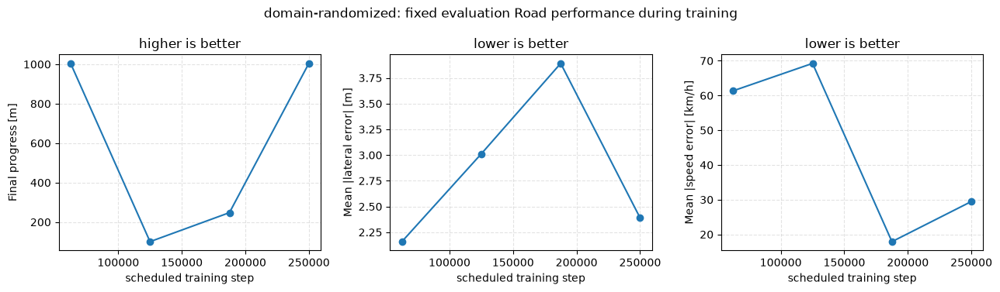

In [257]:
def requested_difference_paths(left, right, prefix=()):
    if isinstance(left, dict) and isinstance(right, dict):
        if set(left) != set(right):
            return {prefix + ("<keys>",)}
        differences = set()
        for key in left:
            differences.update(
                requested_difference_paths(left[key], right[key], prefix + (key,))
            )
        return differences
    return set() if left == right else {prefix}

domain_randomized_config = copy.deepcopy(STAGE_CONFIGS["domain_randomized"])
domain_randomized_requested_snapshot = config_to_dict(domain_randomized_config)

REQUESTED_DIFFERENCES_FROM_COMBINED = tuple(sorted(
    ".".join(path)
    for path in requested_difference_paths(
        combined_requested_snapshot, domain_randomized_requested_snapshot
    )
))
display_records(
    ({"configuration difference": item} for item in REQUESTED_DIFFERENCES_FROM_COMBINED),
    title="Requested differences from the combined stage",
)

domain_randomized_result = train(domain_randomized_config)
domain_randomized_run_dir = Path(domain_randomized_result.run_dir)
domain_randomized_resolved_snapshot = json.loads(
    Path(domain_randomized_result.resolved_config_path).read_text(encoding="utf-8")
)
domain_randomized_scheduled_evaluation_rows = read_scheduled_evaluation_rows(
    domain_randomized_run_dir
)
resolved_roads = domain_randomized_resolved_snapshot["roads"]

DOMAIN_RANDOMIZATION_STAGE_SUMMARY = copy.deepcopy({
    "training_distribution": "fresh random Road on every reset",
    "winning_training_source": resolved_roads["winning_training_source"],
    "training_randomization_controls": resolved_roads["train_randomization"]["controls"],
    "requested_transitions": domain_randomized_requested_snapshot[
        "requested_total_environment_transitions"
    ],
    "actual_transitions": domain_randomized_result.actual_environment_transitions,
    "effective_reward_parameters": domain_randomized_resolved_snapshot["reward"]["effective"][
        "preset_parameters"
    ],
    "fixed_evaluation_road_names": tuple(
        row["road_name"] for row in domain_randomized_scheduled_evaluation_rows
    ),
    **{
        f"mean_{metric_name}": mean_metric(
            domain_randomized_scheduled_evaluation_rows, metric_name
        )
        for metric_name in COMPARISON_METRIC_NAMES
    },
    "run_dir": domain_randomized_run_dir,
    "final_model_path": domain_randomized_result.final_model_path,
})
display_mapping(
    DOMAIN_RANDOMIZATION_STAGE_SUMMARY,
    title="Domain-randomized stage result",
)
DOMAIN_RANDOMIZED_LEARNING_HISTORY = display_learning_history(
    "domain-randomized",
    domain_randomized_run_dir,
    domain_randomized_scheduled_evaluation_rows,
)
domain_randomized_animation_paths = display_run_animations(
    domain_randomized_run_dir,
    title="Final policy trained with Road randomization on the fixed evaluation Road",
)


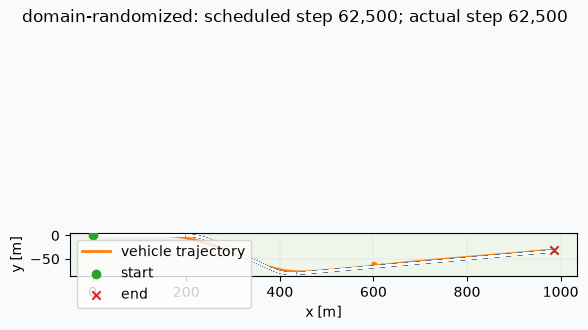

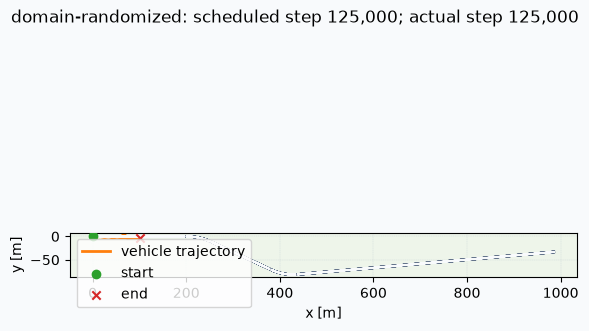

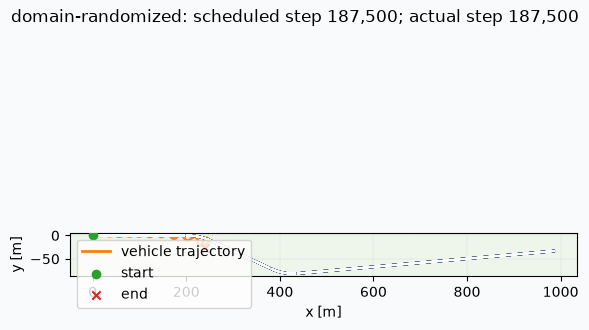

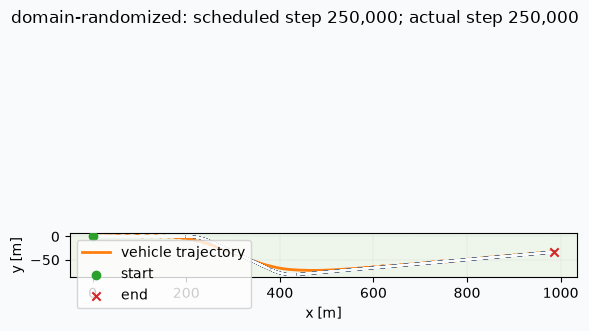

scheduled_step,actual_step,checkpoint_model,trajectory_plot,time_series_plot
62500,62500,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/model_at_evaluation_000062500.zip,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/plots/checkpoint_trajectory_at_000062500.png,—
125000,125000,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/model_at_evaluation_000125000.zip,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/plots/checkpoint_trajectory_at_000125000.png,—
187500,187500,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/model_at_evaluation_000187500.zip,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/plots/checkpoint_trajectory_at_000187500.png,—
250000,250000,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/model_at_evaluation_000250000.zip,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/plots/checkpoint_trajectory_at_000250000.png,—


In [258]:
# Replays saved checkpoint models only; this cell does not retrain the policy.
DOMAIN_RANDOMIZED_CHECKPOINT_TRAJECTORIES = display_checkpoint_trajectories(
    "domain-randomized", domain_randomized_result,
    domain_randomized_scheduled_evaluation_rows,
)

In [259]:
resolved_algorithm = (
    domain_randomized_resolved_snapshot[
        "algorithm"
    ]
)

display_mapping(
    {
        "requested rollout": (
            resolved_algorithm[
                "requested_n_rollout_transitions_per_update"
            ]
        ),
        "SB3 n_steps": (
            resolved_algorithm[
                "constructor_kwargs"
            ]["n_steps"]
        ),
        "actual transitions": (
            domain_randomized_result
            .actual_environment_transitions
        ),
        "final model": (
            domain_randomized_result
            .final_model_path
        ),
    },
    title="Resolved domain-randomized PPO training",
)

field,value
requested rollout,1024
SB3 n_steps,256
actual transitions,250880
final model,notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/final.zip


{'requested rollout': 1024,
 'SB3 n_steps': 256,
 'actual transitions': 250880,
 'final model': 'notebook_outputs/rl-reward-shaping-and-training/domain_randomized/rl-reward-shaping-domain_randomized_20260830-111705/models/final.zip'}

## 4. Comparative evaluation

The combined policy was trained on one fixed Road; the domain-randomized policy was trained on
generated Roads. Both saved policies are loaded from disk and evaluated under three matched
study designs. Equal transition budgets control training effort, but the randomized policy
must learn across more varied experience and may require additional training to converge.


### 4.1 In-distribution transfer

Each policy is evaluated on unseen Roads generated within the randomized training support.
Both policies use the same Road and reset seed in every pair. Seed `20260913` is used for a
trajectory demonstration because its geometry contains straight sections and both left and
right curves; it was selected before policy outcomes were inspected. The broader paired set
tests whether the illustrative comparison persists across several Roads.


In [260]:
IN_DISTRIBUTION_ROAD_GENERATION_SEEDS = (20260913, 20260914, 20260915, 20260916)
IN_DISTRIBUTION_ENVIRONMENT_RESET_SEEDS = (20261000, 20261001, 20261002, 20261003)
OOD_STRESS_ROAD_GENERATION_SEEDS = (20260920, 20260921, 20260922, 20260923)
OOD_STRESS_ENVIRONMENT_RESET_SEEDS = (20261100, 20261101, 20261102, 20261103)

def build_generated_road_cases(
    *, study_name, generation, road_generation_seeds, environment_reset_seeds, case_count
):
    """Build deterministic generated-Road cases for one paired study."""
    if not 1 <= case_count <= len(road_generation_seeds):
        raise ValueError("generated Road case count must be between one and four")
    cases = []
    for case_index, (road_generation_seed, environment_reset_seed) in enumerate(
        zip(
            road_generation_seeds[:case_count],
            environment_reset_seeds[:case_count],
            strict=True,
        )
    ):
        generated_spec = Road.generate_random_spec(
            generation_config=generation, seed=road_generation_seed
        )
        cases.append({
            "study_name": study_name,
            "case_index": case_index,
            "road_name": f"{study_name}-{road_generation_seed}",
            "road_generation_seed": road_generation_seed,
            "environment_reset_seed": environment_reset_seed,
            "road_spec": copy.deepcopy(
                Road(road_spec=generated_spec).requested_road_spec
            ),
        })
    return tuple(cases)

generated_road_case_count = MODE["generated_road_case_count"]
IN_DISTRIBUTION_ROAD_CASES = build_generated_road_cases(
    study_name="in-distribution",
    generation=IN_DISTRIBUTION_EVALUATION_ROAD_GENERATION,
    road_generation_seeds=IN_DISTRIBUTION_ROAD_GENERATION_SEEDS,
    environment_reset_seeds=IN_DISTRIBUTION_ENVIRONMENT_RESET_SEEDS,
    case_count=generated_road_case_count,
)
OOD_STRESS_ROAD_CASES = build_generated_road_cases(
    study_name="ood-stress",
    generation=OOD_STRESS_ROAD_GENERATION,
    road_generation_seeds=OOD_STRESS_ROAD_GENERATION_SEEDS,
    environment_reset_seeds=OOD_STRESS_ENVIRONMENT_RESET_SEEDS,
    case_count=generated_road_case_count,
)
IN_DISTRIBUTION_DEMONSTRATION_CASE = IN_DISTRIBUTION_ROAD_CASES[0]


In [261]:
RL_UNCERTAINTY_PARAMETERS = (
    UniformMultiplierParameter(
        name="mass_multiplier",
        path=("bicycle_model_config", "mass_properties", "mass_kg"),
        low=0.95,
        high=1.05,
    ),
    InitialStateValueParameter(
        name="initial_world_position_y_m",
        path=("world_pose", "y_m"),
        low=-0.25,
        high=0.25,
    ),
)
RL_UNCERTAINTY_SWEEP = UncertaintySweep.monte_carlo(
    RL_UNCERTAINTY_PARAMETERS,
    samples=MODE["sweep_samples"],
    seed=20260810,
)


In [262]:
def evaluate_rl_policies_on_generated_roads(
    *,
    policies,
    cases,
    environment_kwargs,
    tire_force_condition,
    metrics,
    n_steps,
    retained_trajectory_case_indices=(),
):
    """Drive every policy over generated Roads under matched reset seeds."""
    retained_rows = []
    retained_trajectories = {}
    for case in cases:
        for policy_name, policy in policies.items():
            constructor = copy.deepcopy(dict(environment_kwargs))
            constructor["road_spec"] = copy.deepcopy(case["road_spec"])
            environment = gym.make("dreamgym/autonomous_driving_env", **constructor)
            try:
                environment.unwrapped.set_tire_force_condition(tire_force_condition)
                time_series = simulate_policy(
                    environment, n_steps, policy, seed=case["environment_reset_seed"]
                )
                metric_values = compute_autonomous_driving_metrics(time_series, metrics)
                retained_rows.append({
                    "study_name": case["study_name"],
                    "policy_name": policy_name,
                    "case_index": case["case_index"],
                    "road_name": case["road_name"],
                    "road_generation_seed": case["road_generation_seed"],
                    "environment_reset_seed": case["environment_reset_seed"],
                    "terminated": bool(time_series.get("terminated", False)),
                    "truncated": bool(time_series.get("truncated", False)),
                    **{
                        metric_name: float(metric_value)
                        for metric_name, metric_value in metric_values.items()
                    },
                })
                if case["case_index"] in retained_trajectory_case_indices:
                    retained_trajectories[(case["case_index"], policy_name)] = (
                        copy.deepcopy(time_series)
                    )
            finally:
                environment.close()
    return {
        "rows": tuple(copy.deepcopy(retained_rows)),
        "trajectories": copy.deepcopy(retained_trajectories),
    }

def select_rl_concerning_rollout(
    results,
    policy_specs,
    metric_name,
):
    """Select the rollout with the worst finite value of the chosen metric."""

    finite_rows = tuple(
        row
        for row in (
            results.per_rollout_metric_rows or ()
        )
        if math.isfinite(
            float(
                row.get(
                    metric_name,
                    float("nan"),
                )
            )
        )
    )

    if not finite_rows:
        raise RuntimeError(
            "RL sweep has no finite "
            "concerning-case candidates"
        )

    concerning_metric_row = max(
        finite_rows,
        key=lambda row: (
            float(row[metric_name]),
            -int(row["rollout_index"]),
            str(row["policy_name"]),
        ),
    )

    identity = (
        str(
            concerning_metric_row[
                "policy_name"
            ]
        ),
        int(
            concerning_metric_row[
                "rollout_index"
            ]
        ),
    )

    index_row = next(
        row
        for row in results.rollout_index_rows
        if (
            str(row["policy_name"]),
            int(row["rollout_index"]),
        )
        == identity
    )

    policy_spec = next(
        spec
        for spec in policy_specs
        if spec.name == identity[0]
    )

    return (
        concerning_metric_row,
        index_row,
        policy_spec,
    )

In [263]:
def evaluate_loaded_rl_policies(
    *, combined_result, domain_result, in_distribution_cases, ood_stress_cases, sweep
):
    """Reopen both saved policies and run the three comparison studies."""
    with load_model_and_config_for_evaluation(
        combined_result.final_model_path,
        explicit_config=combined_result.resolved_config_path,
    ) as combined_loaded, load_model_and_config_for_evaluation(
        domain_result.final_model_path,
        explicit_config=domain_result.resolved_config_path,
    ) as domain_loaded:
        combined_snapshot = combined_loaded.config.to_dict()
        combined_environment = combined_snapshot["environment"]
        combined_constructor = combined_environment["public_constructor_template"]
        combined_tire_condition = combined_environment["postconstruction_settings"][
            "tire_force_condition"
        ]
        fixed_environment_kwargs = copy.deepcopy(combined_constructor)
        fixed_environment_kwargs["road_spec"] = copy.deepcopy(
            combined_snapshot["roads"]["fixed_evaluation_road_specs"][0]
        )
        RL_EVALUATION_CONFIG = AutonomousDrivingEvaluationConfig(
            n_steps=MODE["sweep_steps"],
            base_env_kwargs=fixed_environment_kwargs,
            include_look_ahead_results=False,
            include_observations=False,
            verbose=0,
        )
        policies = {
            "combined": RLPolicy(combined_loaded.model),
            "domain-randomized": RLPolicy(domain_loaded.model),
        }
        policy_specs = tuple(
            PolicySpec(name=name, policy=policy) for name, policy in policies.items()
        )
        # Study one: unseen Roads within randomized-training support.
        in_distribution_evidence = evaluate_rl_policies_on_generated_roads(
            policies=policies,
            cases=in_distribution_cases,
            environment_kwargs=combined_constructor,
            tire_force_condition=combined_tire_condition,
            metrics=RL_METRICS,
            n_steps=MODE["evaluation_steps"],
            retained_trajectory_case_indices=(0,),
        )
        # Study two: harder Roads extending beyond randomized-training support.
        ood_stress_evidence = evaluate_rl_policies_on_generated_roads(
            policies=policies,
            cases=ood_stress_cases,
            environment_kwargs=combined_constructor,
            tire_force_condition=combined_tire_condition,
            metrics=RL_METRICS,
            n_steps=MODE["evaluation_steps"],
        )
        # Study three: same Road, perturbed vehicle and starting position.
        sweep_results = evaluate_policies_over_sweep(
            policies=policy_specs,
            config=RL_EVALUATION_CONFIG,
            metrics=RL_METRICS,
            sweep=sweep,
            include_per_rollout_metrics=True,
        )
        metric_row, index_row, policy_spec = select_rl_concerning_rollout(
            sweep_results, policy_specs, BUILT_IN_METRIC_NAMES[0]
        )
        concerning_time_series = rerun_sweep_rollout(
            policy_spec, RL_EVALUATION_CONFIG, sweep, index_row
        )
        return copy.deepcopy({
            "in_distribution_rows": in_distribution_evidence["rows"],
            "in_distribution_trajectories": in_distribution_evidence["trajectories"],
            "ood_stress_rows": ood_stress_evidence["rows"],
            "sweep_results": sweep_results,
            "concerning_metric_row": metric_row,
            "concerning_rollout_index_row": index_row,
            "concerning_time_series": concerning_time_series,
        })

rl_final_evidence = evaluate_loaded_rl_policies(
    combined_result=combined_result,
    domain_result=domain_randomized_result,
    in_distribution_cases=IN_DISTRIBUTION_ROAD_CASES,
    ood_stress_cases=OOD_STRESS_ROAD_CASES,
    sweep=RL_UNCERTAINTY_SWEEP,
)


study_name,policy_name,case_index,road_name,road_generation_seed,environment_reset_seed,terminated,truncated,mean_abs_lateral_error_m,mean_abs_speed_error_to_recommended_kph,final_progress_m,fraction_outside_lateral_tolerance,cumulative_overspeed_duration_s,maximum_overspeed_kph,rms_longitudinal_jerk_mps3,rms_steering_request_rate_rad_per_s
in-distribution,combined,0,in-distribution-20260913,20260913,20261000,True,False,1.676,29.59,1053,0.6331,40.45,51.87,21.19,2.937
in-distribution,domain-randomized,0,in-distribution-20260913,20260913,20261000,False,False,2.479,38.52,748.7,0.6807,0,0,18.87,3.438
in-distribution,combined,1,in-distribution-20260914,20260914,20261001,True,False,0.8272,36.75,1231,0.2765,29.8,79.25,7.962,1.031
in-distribution,domain-randomized,1,in-distribution-20260914,20260914,20261001,False,False,3.511,23.85,1221,0.907,0,0,13.35,2.499
in-distribution,combined,2,in-distribution-20260915,20260915,20261002,True,False,2.509,38.49,1132,0.8679,40.5,84.73,14.61,1.988
in-distribution,domain-randomized,2,in-distribution-20260915,20260915,20261002,False,False,5.33,44.28,637.6,0.8256,1,7.002,20.86,3.683
in-distribution,combined,3,in-distribution-20260916,20260916,20261003,True,False,1.505,28.34,1157,0.6214,43.15,62.73,20.76,3.001
in-distribution,domain-randomized,3,in-distribution-20260916,20260916,20261003,False,False,2.176,33.54,885.8,0.5877,0,0,18.15,3.489


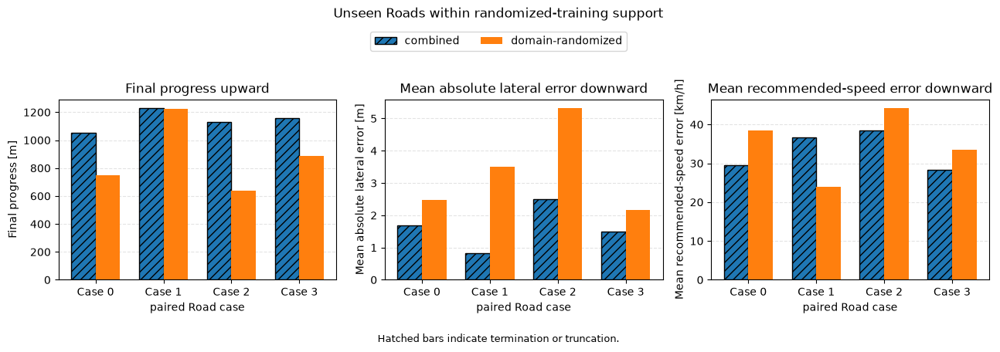

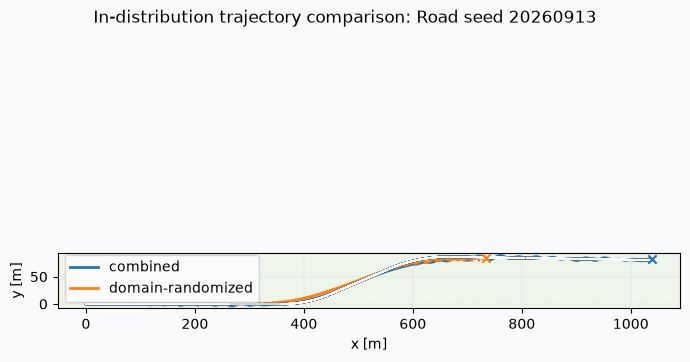

In [264]:
def plot_paired_generated_road_metrics(rows, title):
    metric_specs = (
        ("final_progress_m", "Final progress [m]", "Final progress upward"),
        ("mean_abs_lateral_error_m", "Mean absolute lateral error [m]", "Mean absolute lateral error downward"),
        ("mean_abs_speed_error_to_recommended_kph", "Mean recommended-speed error [km/h]", "Mean recommended-speed error downward"),
    )
    policy_specs = (
        ("combined", "tab:blue", -0.5),
        ("domain-randomized", "tab:orange", 0.5),
    )
    case_indices = sorted({int(row["case_index"]) for row in rows})
    case_positions = np.arange(len(case_indices), dtype=float)
    bar_width = 0.36
    ended_early = False
    figure, axes = plt.subplots(1, 3, figsize=(13.0, 4.4))
    for axis, (metric_name, label, panel_title) in zip(
        axes, metric_specs, strict=True
    ):
        for policy_name, color, offset_multiplier in policy_specs:
            policy_rows = {
                int(row["case_index"]): row
                for row in rows if row["policy_name"] == policy_name
            }
            values = [
                float(policy_rows[index][metric_name]) for index in case_indices
            ]
            bars = axis.bar(
                case_positions + offset_multiplier * bar_width,
                values,
                width=bar_width,
                color=color,
                label=policy_name,
            )
            for bar, index in zip(bars, case_indices, strict=True):
                row = policy_rows[index]
                if bool(row.get("terminated")) or bool(row.get("truncated")):
                    bar.set_hatch("///")
                    bar.set_edgecolor("black")
                    ended_early = True
        axis.set_xlabel("paired Road case")
        axis.set_ylabel(label)
        axis.set_title(panel_title)
        axis.set_xticks(
            case_positions, [f"Case {index}" for index in case_indices]
        )
        axis.set_ylim(bottom=0.0)
        axis.grid(axis="y", linestyle="--", alpha=0.35)
        axis.set_axisbelow(True)
    legend_handles, legend_labels = axes[0].get_legend_handles_labels()
    figure.legend(
        legend_handles, legend_labels, loc="upper center", ncol=2,
        bbox_to_anchor=(0.5, 0.94),
    )
    figure.suptitle(title, y=0.995)
    if ended_early:
        figure.text(
            0.5, 0.01, "Hatched bars indicate termination or truncation.",
            ha="center", fontsize=9,
        )
    figure.tight_layout(rect=(0.0, 0.06, 1.0, 0.88))
    return figure

rl_in_distribution_rows = tuple(
    copy.deepcopy(rl_final_evidence["in_distribution_rows"])
)
display_records(
    rl_in_distribution_rows, title="Paired in-distribution Road evaluation"
)

in_distribution_figure = plot_paired_generated_road_metrics(
    rl_in_distribution_rows,
    "Unseen Roads within randomized-training support",
)
display(in_distribution_figure)
in_distribution_figure_path = save_figure(
    in_distribution_figure, OUTPUT_ROOT / "rl-in-distribution-transfer.png"
)
plt.close(in_distribution_figure)

demonstration_case = IN_DISTRIBUTION_DEMONSTRATION_CASE
demonstration_trajectories = rl_final_evidence["in_distribution_trajectories"]
demonstration_figure, demonstration_axis, _road_handles = plot_road_from_spec(
    demonstration_case["road_spec"],
    title=(
        "In-distribution trajectory comparison: Road seed "
        f"{demonstration_case['road_generation_seed']}"
    ),
    figure_size=(7.0, 5.0),
)
for policy_name, color in (
    ("combined", "tab:blue"),
    ("domain-randomized", "tab:orange"),
):
    time_series = demonstration_trajectories[(0, policy_name)]
    coordinates = np.column_stack((time_series["px"], time_series["py"]))
    visible = coordinates[np.isfinite(coordinates).all(axis=1)]
    if visible.size:
        demonstration_axis.plot(
            visible[:, 0], visible[:, 1], color=color, linewidth=2.0, label=policy_name
        )
        demonstration_axis.scatter(
            visible[-1, 0], visible[-1, 1], color=color, marker="x", zorder=5
        )
demonstration_axis.legend(loc="best")
demonstration_figure.tight_layout(rect=(0.0, 0.0, 1.0, 0.94))
display(demonstration_figure)
in_distribution_trajectory_path = save_figure(
    demonstration_figure, OUTPUT_ROOT / "rl-in-distribution-trajectories.png"
)
plt.close(demonstration_figure)


### 4.2 Out-of-distribution stress test

The harder distribution is retained as an extrapolation study. It includes more Road elements,
smaller curve radii, larger sweeps, and speed limits outside the randomized training ranges.
Failure here does not by itself show that varied training lacks in-distribution transfer benefit.


study_name,policy_name,case_index,road_name,road_generation_seed,environment_reset_seed,terminated,truncated,mean_abs_lateral_error_m,mean_abs_speed_error_to_recommended_kph,final_progress_m,fraction_outside_lateral_tolerance,cumulative_overspeed_duration_s,maximum_overspeed_kph,rms_longitudinal_jerk_mps3,rms_steering_request_rate_rad_per_s
ood-stress,combined,0,ood-stress-20260920,20260920,20261100,True,False,1.806,37.85,1335,0.6398,44.3,75.6,13.95,1.828
ood-stress,domain-randomized,0,ood-stress-20260920,20260920,20261100,False,False,4.164,46.37,772.3,0.8236,0,0,19.19,3.505
ood-stress,combined,1,ood-stress-20260921,20260921,20261101,True,False,3.703,22.71,1313,0.7025,42.65,55.34,14.21,2.006
ood-stress,domain-randomized,1,ood-stress-20260921,20260921,20261101,False,False,5.506,49.22,678.6,0.8391,0,0,20.47,3.704
ood-stress,combined,2,ood-stress-20260922,20260922,20261102,True,False,0.9606,47.69,1633,0.4395,50.4,76.25,13.84,1.404
ood-stress,domain-randomized,2,ood-stress-20260922,20260922,20261102,False,False,5.131,58.4,377.9,0.8501,0.2,2.855,20.3,3.202
ood-stress,combined,3,ood-stress-20260923,20260923,20261103,True,False,2.72,31.57,1233,0.5693,32.4,73.05,11.05,1.71
ood-stress,domain-randomized,3,ood-stress-20260923,20260923,20261103,False,False,4.815,48.65,661,0.9405,0.2,1.879,19.79,3.147


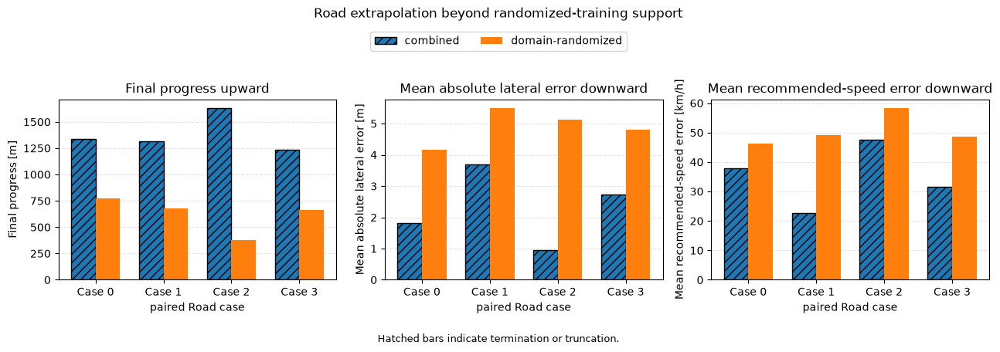

In [265]:
rl_ood_stress_rows = tuple(copy.deepcopy(rl_final_evidence["ood_stress_rows"]))
display_records(
    rl_ood_stress_rows, title="Paired out-of-distribution Road stress test"
)

ood_stress_figure = plot_paired_generated_road_metrics(
    rl_ood_stress_rows,
    "Road extrapolation beyond randomized-training support",
)
display(ood_stress_figure)
ood_stress_figure_path = save_figure(
    ood_stress_figure, OUTPUT_ROOT / "rl-ood-road-stress-test.png"
)
plt.close(ood_stress_figure)


### 4.3 Fixed-Road robustness

Both policies are evaluated on one fixed Road using the same ordered samples of vehicle mass
and initial lateral position. This study measures sensitivity to vehicle and initial-state
variation while holding Road geometry constant.


policy_name,rollout_count,metric_rollout_count,flagged_rollout_count,mean_abs_lateral_error_m__mean,mean_abs_lateral_error_m__median,mean_abs_lateral_error_m__std,mean_abs_lateral_error_m__min,mean_abs_lateral_error_m__max,mean_abs_lateral_error_m__p05,mean_abs_lateral_error_m__p25,mean_abs_lateral_error_m__p75,mean_abs_lateral_error_m__p95,mean_abs_lateral_error_m__worst_case,mean_abs_lateral_error_m__ci95_low,mean_abs_lateral_error_m__ci95_high,mean_abs_lateral_error_m__primary,mean_abs_speed_error_to_recommended_kph__mean,mean_abs_speed_error_to_recommended_kph__median,mean_abs_speed_error_to_recommended_kph__std,mean_abs_speed_error_to_recommended_kph__min,mean_abs_speed_error_to_recommended_kph__max,mean_abs_speed_error_to_recommended_kph__p05,mean_abs_speed_error_to_recommended_kph__p25,mean_abs_speed_error_to_recommended_kph__p75,mean_abs_speed_error_to_recommended_kph__p95,mean_abs_speed_error_to_recommended_kph__worst_case,mean_abs_speed_error_to_recommended_kph__ci95_low,mean_abs_speed_error_to_recommended_kph__ci95_high,mean_abs_speed_error_to_recommended_kph__primary,final_progress_m__mean,final_progress_m__median,final_progress_m__std,final_progress_m__min,final_progress_m__max,final_progress_m__p05,final_progress_m__p25,final_progress_m__p75,final_progress_m__p95,final_progress_m__worst_case,final_progress_m__ci95_low,final_progress_m__ci95_high,final_progress_m__primary,fraction_outside_lateral_tolerance__mean,fraction_outside_lateral_tolerance__median,fraction_outside_lateral_tolerance__std,fraction_outside_lateral_tolerance__min,fraction_outside_lateral_tolerance__max,fraction_outside_lateral_tolerance__p05,fraction_outside_lateral_tolerance__p25,fraction_outside_lateral_tolerance__p75,fraction_outside_lateral_tolerance__p95,fraction_outside_lateral_tolerance__worst_case,fraction_outside_lateral_tolerance__ci95_low,fraction_outside_lateral_tolerance__ci95_high,fraction_outside_lateral_tolerance__primary,cumulative_overspeed_duration_s__mean,cumulative_overspeed_duration_s__median,cumulative_overspeed_duration_s__std,cumulative_overspeed_duration_s__min,cumulative_overspeed_duration_s__max,cumulative_overspeed_duration_s__p05,cumulative_overspeed_duration_s__p25,cumulative_overspeed_duration_s__p75,cumulative_overspeed_duration_s__p95,cumulative_overspeed_duration_s__worst_case,cumulative_overspeed_duration_s__ci95_low,cumulative_overspeed_duration_s__ci95_high,cumulative_overspeed_duration_s__primary,maximum_overspeed_kph__mean,maximum_overspeed_kph__median,maximum_overspeed_kph__std,maximum_overspeed_kph__min,maximum_overspeed_kph__max,maximum_overspeed_kph__p05,maximum_overspeed_kph__p25,maximum_overspeed_kph__p75,maximum_overspeed_kph__p95,maximum_overspeed_kph__worst_case,maximum_overspeed_kph__ci95_low,maximum_overspeed_kph__ci95_high,maximum_overspeed_kph__primary,rms_longitudinal_jerk_mps3__mean,rms_longitudinal_jerk_mps3__median,rms_longitudinal_jerk_mps3__std,rms_longitudinal_jerk_mps3__min,rms_longitudinal_jerk_mps3__max,rms_longitudinal_jerk_mps3__p05,rms_longitudinal_jerk_mps3__p25,rms_longitudinal_jerk_mps3__p75,rms_longitudinal_jerk_mps3__p95,rms_longitudinal_jerk_mps3__worst_case,rms_longitudinal_jerk_mps3__ci95_low,rms_longitudinal_jerk_mps3__ci95_high,rms_longitudinal_jerk_mps3__primary,rms_steering_request_rate_rad_per_s__mean,rms_steering_request_rate_rad_per_s__median,rms_steering_request_rate_rad_per_s__std,rms_steering_request_rate_rad_per_s__min,rms_steering_request_rate_rad_per_s__max,rms_steering_request_rate_rad_per_s__p05,rms_steering_request_rate_rad_per_s__p25,rms_steering_request_rate_rad_per_s__p75,rms_steering_request_rate_rad_per_s__p95,rms_steering_request_rate_rad_per_s__worst_case,rms_steering_request_rate_rad_per_s__ci95_low,rms_steering_request_rate_rad_per_s__ci95_high,rms_steering_request_rate_rad_per_s__primary
combined,16,0,16,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,

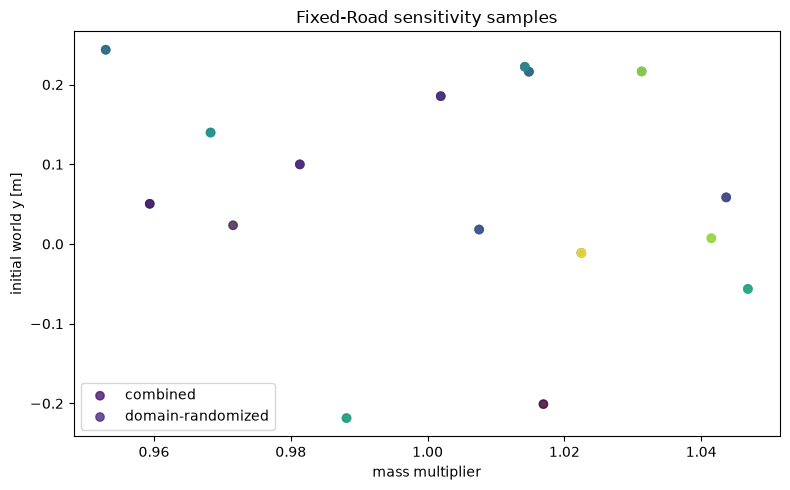

In [266]:
rl_sweep_results = rl_final_evidence["sweep_results"]
rl_fixed_road_sweep_rows = tuple(copy.deepcopy(rl_sweep_results.aggregate_rows))
rl_fixed_road_rollout_rows = tuple(
    copy.deepcopy(rl_sweep_results.per_rollout_metric_rows or ())
)
rl_fixed_road_index_rows = tuple(copy.deepcopy(rl_sweep_results.rollout_index_rows))
display_records(
    rl_fixed_road_sweep_rows, title="Fixed-Road uncertainty summary"
)

fixed_sweep_figure, fixed_sweep_axis = plt.subplots(figsize=(8.0, 5.0))
try:
    for policy_name in ("combined", "domain-randomized"):
        policy_rows = [
            row for row in rl_fixed_road_rollout_rows
            if row["policy_name"] == policy_name
        ]
        fixed_sweep_axis.scatter(
            [row["mass_multiplier"] for row in policy_rows],
            [row["initial_world_position_y_m"] for row in policy_rows],
            c=[row[BUILT_IN_METRIC_NAMES[0]] for row in policy_rows],
            label=policy_name,
            alpha=0.8,
        )
    fixed_sweep_axis.set_xlabel("mass multiplier")
    fixed_sweep_axis.set_ylabel("initial world y [m]")
    fixed_sweep_axis.set_title("Fixed-Road sensitivity samples")
    fixed_sweep_axis.legend()
    fixed_sweep_figure.tight_layout()
    display(fixed_sweep_figure)
    fixed_sweep_figure_path = save_figure(
        fixed_sweep_figure, OUTPUT_ROOT / "rl-fixed-road-uncertainty.png"
    )
finally:
    plt.close(fixed_sweep_figure)


In [267]:
FIXED_ROAD_COMPLETION_THRESHOLD_M = (
    0.99
    * max(
        float(row["final_progress_m"])
        for row in rl_fixed_road_rollout_rows
    )
)

ROBUSTNESS_METRIC_NAMES = (
    "mean_abs_lateral_error_m",
    "mean_abs_speed_error_to_recommended_kph",
    "final_progress_m",
    "fraction_outside_lateral_tolerance",
    "cumulative_overspeed_duration_s",
    "maximum_overspeed_kph",
    "rms_longitudinal_jerk_mps3",
    "rms_steering_request_rate_rad_per_s",
)


def finite_metric_mean(rows, metric_name):
    values = np.asarray(
        [
            float(row.get(metric_name, float("nan")))
            for row in rows
        ],
        dtype=np.float64,
    )

    values = values[np.isfinite(values)]

    if values.size == 0:
        return float("nan")

    return float(np.mean(values))


robustness_summary_rows = []

for policy_name in (
    "combined",
    "domain-randomized",
):
    policy_rows = [
        row
        for row in rl_fixed_road_rollout_rows
        if row["policy_name"] == policy_name
    ]

    completion_flags = [
        float(row["final_progress_m"])
        >= FIXED_ROAD_COMPLETION_THRESHOLD_M
        for row in policy_rows
    ]

    termination_without_completion_count = sum(
        bool(row.get("terminated", False))
        and not completed
        for row, completed in zip(
            policy_rows,
            completion_flags,
            strict=True,
        )
    )

    summary_row = {
        "policy_name": policy_name,
        "rollout_count": len(policy_rows),
        "completion_count": int(
            sum(completion_flags)
        ),
        "completion_rate": float(
            np.mean(completion_flags)
        ),
        "termination_without_completion_count": int(
            termination_without_completion_count
        ),
        "truncation_count": int(
            sum(
                bool(row.get("truncated", False))
                for row in policy_rows
            )
        ),
    }

    for metric_name in ROBUSTNESS_METRIC_NAMES:
        summary_row[
            f"{metric_name}__mean"
        ] = finite_metric_mean(
            policy_rows,
            metric_name,
        )

    robustness_summary_rows.append(summary_row)


display_records(
    robustness_summary_rows,
    title=(
        "Corrected Fixed-Road robustness summary "
        "including completed episodes"
    ),
)

policy_name,rollout_count,completion_count,completion_rate,termination_without_completion_count,truncation_count,mean_abs_lateral_error_m__mean,mean_abs_speed_error_to_recommended_kph__mean,final_progress_m__mean,fraction_outside_lateral_tolerance__mean,cumulative_overspeed_duration_s__mean,maximum_overspeed_kph__mean,rms_longitudinal_jerk_mps3__mean,rms_steering_request_rate_rad_per_s__mean
combined,16,16,1,0,0,1.586,22.96,1004,0.3467,24.99,47.93,6.15,0.6383
domain-randomized,16,0,0,0,0,4.113,47.3,509.4,0.8566,0,0,18.86,3.342


({'policy_name': 'combined',
  'rollout_count': 16,
  'completion_count': 16,
  'completion_rate': 1.0,
  'termination_without_completion_count': 0,
  'truncation_count': 0,
  'mean_abs_lateral_error_m__mean': 1.5855793001733356,
  'mean_abs_speed_error_to_recommended_kph__mean': 22.957187611405818,
  'final_progress_m__mean': 1004.319091796875,
  'fraction_outside_lateral_tolerance__mean': 0.3467209772582244,
  'cumulative_overspeed_duration_s__mean': 24.993749999999913,
  'maximum_overspeed_kph__mean': 47.93434009552002,
  'rms_longitudinal_jerk_mps3__mean': 6.1497123554879565,
  'rms_steering_request_rate_rad_per_s__mean': 0.6382535083306227},
 {'policy_name': 'domain-randomized',
  'rollout_count': 16,
  'completion_count': 0,
  'completion_rate': 0.0,
  'termination_without_completion_count': 0,
  'truncation_count': 0,
  'mean_abs_lateral_error_m__mean': 4.112638654510059,
  'mean_abs_speed_error_to_recommended_kph__mean': 47.29591914459817,
  'final_progress_m__mean': 509.448825

The generic uncertainty-sweep aggregate excluded terminated rollouts.
In this environment, termination can represent successful Road completion,
so all 16 completed fixed-Road policy rollouts were incorrectly excluded
from its metric aggregation, producing NaN summary values.

Therefore, the robustness comparison below recomputes the metric means from
the per-rollout results while retaining successfully completed episodes.
Completion is reported separately from failure/truncation.

### 4.4 Inspect a concerning rollout

The notebook selects one rollout for trajectory-level inspection, prioritizing terminated or
truncated runs and otherwise using the largest lateral-error metric.


field,value
policy_name,domain-randomized
rollout_index,5
terminated,False
truncated,False
mass_multiplier,1.022
initial_world_position_y_m,-0.01124
mean_abs_lateral_error_m,5.058
mean_abs_speed_error_to_recommended_kph,57.42
final_progress_m,342.1
fraction_outside_lateral_tolerance,0.8548


field,value
policy_name,domain-randomized
rollout_index,5
terminated,False
truncated,False
steps_recorded,0
mass_multiplier,1.022
initial_world_position_y_m,-0.01124


field,value
steps_recorded,1501


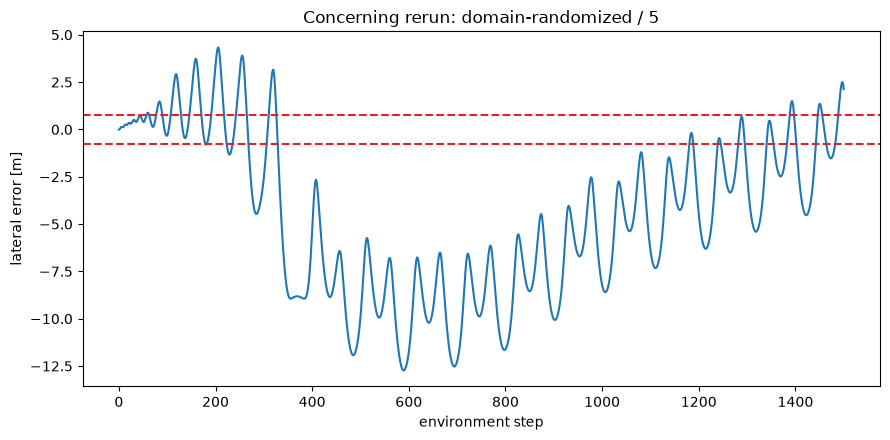

In [268]:
rl_concerning_metric_row = copy.deepcopy(rl_final_evidence["concerning_metric_row"])
rl_concerning_rollout_index_row = copy.deepcopy(
    rl_final_evidence["concerning_rollout_index_row"]
)
rl_concerning_time_series = copy.deepcopy(rl_final_evidence["concerning_time_series"])
concerning_identity = (
    rl_concerning_metric_row["policy_name"],
    rl_concerning_metric_row["rollout_index"],
)
concerning_lateral_error = rl_concerning_time_series["lateral_error_from_target_line"]
RL_CONCERNING_RERUN_EVIDENCE = copy.deepcopy({
    "metric_row": rl_concerning_metric_row,
    "rollout_index_row": rl_concerning_rollout_index_row,
    "steps_recorded": len(concerning_lateral_error),
})
display_mapping(
    rl_concerning_metric_row, title="Selected concerning metric row"
)
display_mapping(
    rl_concerning_rollout_index_row, title="Selected rollout identity"
)
display_mapping(
    {"steps_recorded": len(concerning_lateral_error)},
    title="Rerun summary",
)

concerning_figure, concerning_axis = plt.subplots(figsize=(9.0, 4.5))
try:
    concerning_axis.plot(np.arange(len(concerning_lateral_error)), concerning_lateral_error)
    concerning_axis.axhline(LATERAL_TOLERANCE_M, color="tab:red", linestyle="--")
    concerning_axis.axhline(-LATERAL_TOLERANCE_M, color="tab:red", linestyle="--")
    concerning_axis.set_xlabel("environment step")
    concerning_axis.set_ylabel("lateral error [m]")
    concerning_axis.set_title(
        f"Concerning rerun: {concerning_identity[0]} / {concerning_identity[1]}"
    )
    concerning_figure.tight_layout()
    display(concerning_figure)
    concerning_figure_path = save_figure(
        concerning_figure, OUTPUT_ROOT / "rl-concerning-rerun.png"
    )
finally:
    plt.close(concerning_figure)


### 4.5 Export results

The notebook writes the evaluation tables and figures beneath
`notebook_outputs/rl-reward-shaping-and-training/`. The displayed path mapping identifies the
files available for subsequent comparison or a written analysis.


In [269]:
RL_EXPORT_TABLES = (
    ("rl-in-distribution-transfer-results.csv", rl_in_distribution_rows),
    ("rl-ood-stress-results.csv", rl_ood_stress_rows),
(
    "rl-fixed-road-robustness-summary.csv",
    tuple(robustness_summary_rows),
),    ("rl-fixed-road-sweep-rollouts.csv", rl_fixed_road_rollout_rows),
    ("rl-concerning-metric-row.csv", (rl_concerning_metric_row,)),
    ("rl-concerning-rollout-index.csv", (rl_concerning_rollout_index_row,)),
)
rl_export_csv_paths = []
for export_name, export_rows in RL_EXPORT_TABLES:
    export_path = OUTPUT_ROOT / export_name
    with export_path.open("w", newline="", encoding="utf-8") as export_handle:
        export_writer = csv.DictWriter(
            export_handle, fieldnames=tuple(export_rows[0])
        )
        export_writer.writeheader()
        export_writer.writerows(export_rows)
    rl_export_csv_paths.append(export_path)

RL_EXPORT_PATHS = (
    *rl_export_csv_paths,
    in_distribution_figure_path,
    in_distribution_trajectory_path,
    ood_stress_figure_path,
    fixed_sweep_figure_path,
    concerning_figure_path,
)
display_records(
    ({"artifact": Path(path).name, "path": path} for path in RL_EXPORT_PATHS),
    title="Exported analysis files",
)


artifact,path
rl-in-distribution-transfer-results.csv,notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-transfer-results.csv
rl-ood-stress-results.csv,notebook_outputs/rl-reward-shaping-and-training/rl-ood-stress-results.csv
rl-fixed-road-robustness-summary.csv,notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-robustness-summary.csv
rl-fixed-road-sweep-rollouts.csv,notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-sweep-rollouts.csv
rl-concerning-metric-row.csv,notebook_outputs/rl-reward-shaping-and-training/rl-concerning-metric-row.csv
rl-concerning-rollout-index.csv,notebook_outputs/rl-reward-shaping-and-training/rl-concerning-rollout-index.csv
rl-in-distribution-transfer.png,notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-transfer.png
rl-in-distribution-trajectories.png,notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-trajectories.png
rl-ood-road-stress-test.png,notebook_outputs/rl-reward-shaping-and-training/rl-ood-road-stress-test.png
rl-fixed-road-uncertainty.png,notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-uncertainty.png


({'artifact': 'rl-in-distribution-transfer-results.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-transfer-results.csv')},
 {'artifact': 'rl-ood-stress-results.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-ood-stress-results.csv')},
 {'artifact': 'rl-fixed-road-robustness-summary.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-robustness-summary.csv')},
 {'artifact': 'rl-fixed-road-sweep-rollouts.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-sweep-rollouts.csv')},
 {'artifact': 'rl-concerning-metric-row.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-concerning-metric-row.csv')},
 {'artifact': 'rl-concerning-rollout-index.csv',
  'path': PosixPath('notebook_outputs/rl-reward-shaping-and-training/rl-concerning-rollout-index.csv')},
 {'artifact': 'rl-in-distribution-transfer.png',
  'path': PosixPa

In [270]:
RESULTS_SUMMARY = copy.deepcopy({
    "reward design": (
        "Which reward terms shaped the observed behaviour, and what "
        "trajectory evidence supports that explanation?"
    ),
    "in-distribution transfer": (
        "How do the policies differ on unseen Roads within the randomized-training "
        "support, and does the demonstration persist across the paired cases?"
    ),
    "out-of-distribution stress": (
        "What happens when Road geometry and speeds extend beyond the randomized-training "
        "ranges?"
    ),
    "fixed-Road sensitivity": (
        "How do mass and initial lateral position affect each policy "
        "when the Road and sweep samples are held fixed?"
    ),
    "evidence": {
        "reward_term_rows": combined_reward_term_rows,
        "in_distribution_rows": rl_in_distribution_rows,
        "ood_stress_rows": rl_ood_stress_rows,
       "fixed_road_sweep_rows": copy.deepcopy(
    robustness_summary_rows
),
        "concerning_rerun": RL_CONCERNING_RERUN_EVIDENCE,
    },
    "export_paths": RL_EXPORT_PATHS,
})
display_mapping(
    {key: value for key, value in RESULTS_SUMMARY.items() if key != "evidence"},
    title="Analysis questions and exported files",
)
display_records(
    (
        {"evidence": "reward decomposition", "rows": len(combined_reward_term_rows)},
        {"evidence": "in-distribution Roads", "rows": len(rl_in_distribution_rows)},
        {"evidence": "out-of-distribution stress Roads", "rows": len(rl_ood_stress_rows)},
{
    "evidence": "fixed-Road sweep",
    "rows": len(robustness_summary_rows),
},        {"evidence": "concerning rerun", "rows": 1},
    ),
    title="Evidence available for the final analysis",
)


field,value
reward design,"Which reward terms shaped the observed behaviour, and what trajectory evidence supports that explanation?"
in-distribution transfer,"How do the policies differ on unseen Roads within the randomized-training support, and does the demonstration persist across the paired cases?"
out-of-distribution stress,What happens when Road geometry and speeds extend beyond the randomized-training ranges?
fixed-Road sensitivity,How do mass and initial lateral position affect each policy when the Road and sweep samples are held fixed?
export_paths,"[""notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-transfer-results.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-ood-stress-results.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-robustness-summary.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-sweep-rollouts.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-concerning-metric-row.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-concerning-rollout-index.csv"", ""notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-transfer.png"", ""notebook_outputs/rl-reward-shaping-and-training/rl-in-distribution-trajectories.png"", ""notebook_outputs/rl-reward-shaping-and-training/rl-ood-road-stress-test.png"", ""notebook_outputs/rl-reward-shaping-and-training/rl-fixed-road-uncertainty.png"", ""notebook_outputs/rl-reward-shaping-and-training/rl-concerning-rerun.png""]"


evidence,rows
reward decomposition,817
in-distribution Roads,8
out-of-distribution stress Roads,8
fixed-Road sweep,2
concerning rerun,1


({'evidence': 'reward decomposition', 'rows': 817},
 {'evidence': 'in-distribution Roads', 'rows': 8},
 {'evidence': 'out-of-distribution stress Roads', 'rows': 8},
 {'evidence': 'fixed-Road sweep', 'rows': 2},
 {'evidence': 'concerning rerun', 'rows': 1})

## Appendix A. Retained superseded speed-lookahead experiment

These cells preserve the original stronger-lane, explicitly configured
learning-rate experiment and its full benchmark. It is excluded from the
assignment's controlled baseline-vs-lookahead comparison. Set
`RUN_RETAINED_SUPERSEDED_LOOKAHEAD = True` only to reproduce it.


In [271]:
RUN_RETAINED_SUPERSEDED_LOOKAHEAD = False


In [272]:
if RUN_RETAINED_SUPERSEDED_LOOKAHEAD:
    # Stronger lane reward only for this experiment.
    SPEED_LOOKAHEAD_REWARD_PARAMETERS = (
        copy.deepcopy(
            SELECTED_REWARD_PARAMETERS
        )
    )

    SPEED_LOOKAHEAD_REWARD_PARAMETERS[
        "k_lane"
    ] = 2.0

    display_mapping(
        SPEED_LOOKAHEAD_REWARD_PARAMETERS,
        title=(
            "Speed-lookahead reward params "
            "reward parameters"
        ),
    )


In [273]:
if RUN_RETAINED_SUPERSEDED_LOOKAHEAD:
    SPEED_LOOKAHEAD_STAGE = copy.deepcopy(
        STAGE_SETUP["combined"]
    )

    speed_lookahead_config = build_training_config(
        "speed_lookahead_lr_1e4",
        SPEED_LOOKAHEAD_STAGE,
        SPEED_LOOKAHEAD_REWARD_PARAMETERS,
        FINAL_RL_MODE,
        OUTPUT_ROOT,
        include_next_speed_change_observations=True,
        learning_rate=3e-4,
    )

    speed_lookahead_result = train(
        speed_lookahead_config
    )


In [274]:
if RUN_RETAINED_SUPERSEDED_LOOKAHEAD:
    speed_lookahead_run_dir = Path(
        speed_lookahead_result.run_dir
    )

    speed_lookahead_requested_snapshot = config_to_dict(
        speed_lookahead_config
    )

    speed_lookahead_resolved_snapshot = json.loads(
        Path(
            speed_lookahead_result.resolved_config_path
        ).read_text(
            encoding="utf-8"
        )
    )

    speed_lookahead_scheduled_rows = (
        read_scheduled_evaluation_rows(
            speed_lookahead_run_dir
        )
    )

    SPEED_LOOKAHEAD_LEARNING_HISTORY = (
        display_learning_history(
            "speed-lookahead",
            speed_lookahead_run_dir,
            speed_lookahead_scheduled_rows,
        )
    )


In [275]:
if RUN_RETAINED_SUPERSEDED_LOOKAHEAD:
    # ------------------------------------------------------------
    # Full client-metric evaluation of every speed-lookahead checkpoint
    # ------------------------------------------------------------

    def evaluate_saved_checkpoint_client_metrics(
        checkpoint_path,
        resolved_config_path,
        candidate_name,
    ):
        with load_model_and_config_for_evaluation(
            checkpoint_path,
            explicit_config=resolved_config_path,
        ) as loaded:

            snapshot = loaded.config.to_dict()

            environment_record = snapshot[
                "environment"
            ]

            environment_kwargs = copy.deepcopy(
                environment_record[
                    "public_constructor_template"
                ]
            )

            # Same held-out fixed evaluation road for every checkpoint.
            environment_kwargs["road_spec"] = copy.deepcopy(
                snapshot[
                    "roads"
                ][
                    "fixed_evaluation_road_specs"
                ][0]
            )

            environment = gym.make(
                "dreamgym/autonomous_driving_env",
                **environment_kwargs,
            )

            try:
                environment.unwrapped.set_tire_force_condition(
                    environment_record[
                        "postconstruction_settings"
                    ][
                        "tire_force_condition"
                    ]
                )

                policy = RLPolicy(
                    loaded.model
                )

                time_series = simulate_policy(
                    environment,
                    MODE["evaluation_steps"],
                    policy,
                    seed=RL_SEEDS[
                        "fixed_road_environment_reset_seed"
                    ],
                )

                metric_values = (
                    compute_autonomous_driving_metrics(
                        time_series,
                        RL_METRICS,
                    )
                )

            finally:
                environment.close()

        return {
            "candidate": candidate_name,

            "terminated": rollout_flag(
                time_series,
                "terminated",
            ),

            "truncated": rollout_flag(
                time_series,
                "truncated",
            ),

            **{
                metric_name: float(metric_value)
                for metric_name, metric_value
                in metric_values.items()
            },
        }

    speed_lookahead_checkpoint_paths = tuple(
        sorted(
            speed_lookahead_run_dir.glob(
                "models/model_at_evaluation_*.zip"
            )
        )
    )

    SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS = []

    for checkpoint_path in speed_lookahead_checkpoint_paths:

        checkpoint_step = int(
            checkpoint_path.stem.rsplit(
                "_",
                1,
            )[-1]
        )

        row = evaluate_saved_checkpoint_client_metrics(
            checkpoint_path,
            speed_lookahead_result.resolved_config_path,
            (
                "speed_lookahead_"
                f"{checkpoint_step}"
            ),
        )

        row["checkpoint_step"] = (
            checkpoint_step
        )

        SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS.append(
            row
        )


    SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS = tuple(
        sorted(
            SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS,
            key=lambda row: row[
                "checkpoint_step"
            ],
        )
    )

    CLIENT_BENCHMARK_COLUMNS = (
        "candidate",
        "checkpoint_step",

        # Task completion
        "final_progress_m",

        # Client requirement 1:
        # Do not exceed recommended speed
        "cumulative_overspeed_duration_s",
        "maximum_overspeed_kph",

        # Client requirement 2:
        # Generally drive at recommended speed
        "mean_abs_speed_error_to_recommended_kph",

        # Client requirement 3:
        # Smooth acceleration/deceleration
        "rms_longitudinal_jerk_mps3",

        # Client requirement 4:
        # Smooth lane keeping
        "mean_abs_lateral_error_m",
        "fraction_outside_lateral_tolerance",
        "rms_steering_request_rate_rad_per_s",

        "terminated",
        "truncated",
    )


    display_records(
        SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS,
        columns=CLIENT_BENCHMARK_COLUMNS,
        title=(
            "Speed-lookahead checkpoints: "
            "client-requirement benchmark"
        ),
    )


In [276]:
if RUN_RETAINED_SUPERSEDED_LOOKAHEAD:
    BASELINE_CLIENT_BENCHMARK_ROW = {
        "candidate": "baseline_no_lookahead",
        "checkpoint_step": 250_000,

        **{
            metric_name: float(metric_value)
            for metric_name, metric_value
            in combined_reload_metric_row.items()
        },
    }

    CLIENT_REQUIREMENT_BENCHMARK = (
        BASELINE_CLIENT_BENCHMARK_ROW,
        *SPEED_LOOKAHEAD_CLIENT_METRIC_ROWS,
    )

    display_records(
        CLIENT_REQUIREMENT_BENCHMARK,
        columns=CLIENT_BENCHMARK_COLUMNS,
        title=(
            "Baseline vs speed-lookahead: "
            "full client-requirement benchmark"
        ),
    )
